# 9주차 ESP32 단계별 실습 튜토리얼

9주차 최신 GitHub의 예제1~8을 전체 코드와 함께 순서대로 따라한다. 소스 기준 커밋: fd880ace44c762a54c879e4b7854185eb0e66d66. 기존 초안은 archive_chatgpt_esp32cam에 보관되어 있으며 이 튜토리얼의 카메라는 **ESP32-S3-WROOM CAM** 기준이다.

## 완성 결과와 자료 바로가기

- [최신 강의 핀배치 Wokwi 프로젝트](https://wokwi.com/projects/479736452457149441)
- [Colab 코드 열람·이미지 전처리 노트북](https://colab.research.google.com/drive/1_SMAJg0a3BgxY_sKbMJ5DE693Ix1MtNQ)
- [Drive 사진·노트북·전체 ZIP](https://drive.google.com/drive/folders/1xdbvMamFaB5V9CI1l0oM3yMn-CN7I-3g)
- [전체 실습자료 ZIP](https://drive.google.com/file/d/1vqUe7Kru7siSUJaAPQDqCUOXfM6zEEeS/view?usp=drivesdk)
- [GitHub 튜토리얼](https://github.com/itlects/2026-1_ai-convergence-apply/tree/main/week09_esp32_ai_image/tutorial)
- [9주차 강의자료](https://app.notion.com/p/40db2e6bf80780959892f76afaec8609)

![최신 GPIO 회로 Wokwi 실행 화면](https://raw.githubusercontent.com/itlects/2026-1_ai-convergence-apply/main/week09_esp32_ai_image/tutorial/assets/wokwi_verified.jpg)

위 그림은 Wokwi 실행 캡처이며 실물 사진이 아니다. [Drive 원본 화면](https://drive.google.com/file/d/1UXo5pwGp-YxoJ4fWDJQz0bFBu5laBIuS/view?usp=drivesdk). GPIO 연결도와 S3 보드 그림도 Drive에 저장되어 있다.

**핀배치 통일:** 이전 Wokwi 프로젝트(LED16·17·18·19 / 버튼13·14·25·26)와 이 최신 회로를 섞지 않는다. 이 페이지의 모든 GPIO 실습은 아래 최신 표를 따른다.

## 0. 준비물·이론·실행 방법

| 구분 | 실행 위치·준비물 |
| --- | --- |
| 예제1~5 | ESP32-DevKitC V4, 버튼4, LED4, 220Ω4, 저전류 수동 피에조1, 보호용100Ω1, 브레드보드·점퍼선 / 또는 Wokwi |
| 예제6~8 | 실제 ESP32-S3-WROOM CAM(Freenove 호환, 카메라·microSD 내장), FAT32 microSD, USB 데이터 케이블 |
| 전처리 | Colab / 촬영 JPEG 또는 합성 시연 이미지 |

### GPIO·풀업·채터링

- GPIO: 입력에서 버튼의 HIGH/LOW를 읽고 출력에서 LED·부저를 제어하는 범용 입출력 핀이다.
- OUTPUT은 digitalWrite로 HIGH/LOW를 출력한다. LED에는 전류 제한용 직렬 저항이 필요하다.
- INPUT_PULLUP은 내부 저항으로 입력을 HIGH로 유지한다. 버튼으로 GND에 연결하면 LOW가 된다.
- 채터링은 접점이 눌리는 순간 여러 번 붙었다 떨어지는 현상이다. 예제5는 30ms 동안 안정된 변화만 확정하고 HIGH→LOW에서 한 번 토글한다.
- delay는 해당 시간 동안 loop 진행을 멈춘다. millis는 경과 시간을 비교할 수 있게 한다. 예제5에도 축하 멜로디용 delay가 남아 있어 완전한 비차단 코드는 아니다.

### 최신 GPIO 연결표

| 부품 | GPIO | 연결 |
| --- | --- | --- |
| LED1~4 | 32, 33, 25, 26 | GPIO → 220Ω → LED A(긴 다리,+), C(짧은 다리,-) → GND |
| 버튼1~4 | 23, 22, 21, 19 | GPIO ↔ 버튼 ↔ GND, INPUT_PULLUP |
| 수동 피에조 | 27 | GPIO → 보호용100Ω → (+), (-) → GND |

원본 예제는 피에조 직결을 제시한다. 이 Wokwi 회로는 저전류 수동 피에조에 100Ω 보호 저항을 추가했으며 제어 핀은 같다. 자석식·고전류 부저는 GPIO 직결하지 않고 드라이버가 필요하다. 부저 능동/수동 여부를 외관만으로 단정하지 말고 부품 사양을 확인한다.

![DevKitC V4 최신 연결도](https://raw.githubusercontent.com/itlects/2026-1_ai-convergence-apply/main/week09_esp32_ai_image/tutorial/assets/gpio_wiring.png)

[GPIO 연결도 Drive 파일](https://drive.google.com/file/d/1SaqmXXEEHFodEyb1stklolR3MqQhrfXF/view?usp=drivesdk)

**배선:** 4핀 택트 스위치는 같은 접점 그룹의 두 다리가 내부에서 연결될 수 있다. 도통을 확인해 눌렀을 때만 GPIO와 GND가 연결되게 한다. Wokwi는 1.l과 2.r처럼 서로 다른 그룹을 사용한다. 회로의 위아래 순서는 핀 위치에 맞췄으므로 부품 번호·GPIO 라벨로 찾는다.

**전원:** GPIO는 3.3V 로직이다. GPIO6~11은 내부 플래시용, GPIO34~39는 입력 전용이며 내부 풀업이 없다(일반 ESP32 기준). 실제 보드의 칩·핀 표기를 확인하고 배선 변경 전 전원을 끈다. USB와 외부 전원을 임의 병렬 연결하지 않는다.

### Arduino IDE 설정

1. 보드 매니저에서 esp32 by Espressif Systems 3.x를 설치한다.
2. DevKitC V4는 ESP32 Dev Module과 해당 COM 포트를 선택한다.
3. S3 카메라는 다음 표를 사용하되 제조사·메모리 표기를 대조한다. 다른 제조사 S3 보드는 카메라 핀·SD핀·PSRAM이 다를 수 있다.
4. 연결한 USB 데이터 포트에 맞춰 CDC 설정을 선택하고 시리얼은 115200으로 연다.

| 항목 | S3 CAM(Freenove 호환) |
| --- | --- |
| Board | ESP32S3 Dev Module |
| PSRAM | OPI PSRAM (해당 보드 메모리 확인) |
| Flash | N8R8=8MB, N16R8=16MB |
| Partition | 자료 기준 8M with spiffs (3MB APP/1.5MB SPIFFS), 설치 코어의 실제 메뉴 확인 |
| USB CDC On Boot | COM/UART 포트 Disabled, USB/OTG 포트 Enabled |
| microSD 내부핀 | CMD38, CLK39, D0 40 / SD_MMC 1비트 |

### Wokwi에서 예제1~5 따라하기

1. 위 최신 Wokwi 링크를 열고 로그인 후 Save 메뉴에서 자신의 사본을 만든다.
2. 정지 → sketch.ino 전체 선택 → 아래 단계의 전체 코드로 교체 → ▶ 실행한다. 코드를 이전 코드 뒤에 추가하지 않는다.
3. diagram.json은 같은 완성 회로를 유지한다. 단계에서 쓰지 않는 부품은 연결된 채 둔다.
4. 회로의 버튼 또는 키1~4를 사용한다. 키가 코드에 입력되면 회로 영역으로 포커스를 옮긴다.
5. 예제5까지 끝나면 완성 코드를 적용해 저장하고 URL·실행 화면을 기록한다.

**Colab 역할:** C++ 코드를 구문 강조로 보여주고 .ino 파일로 저장한다. Colab Python 런타임에서 GPIO·카메라를 직접 실행하지 않는다. 디바운스 모형과 이미지 전처리는 Python으로 실행되며, 펌웨어 실행은 Wokwi 또는 Arduino IDE·실물 보드에서 수행한다.

**180분 진행:** 준비15분 → 예제1~4 40분 → 예제5 25분 → 예제6~8 55분 → 전처리30분 → 기록15분. 카메라 미보유자는 S3 코드·흐름 학습 후 합성 시연 데이터로 전처리한다.


In [1]:
from pathlib import Path
from IPython.display import Code, display, FileLink
Path("esp32_sources").mkdir(exist_ok=True)
print("C++는 표시·저장하고 Wokwi/Arduino IDE에서 실행합니다.")

C++는 표시·저장하고 Wokwi/Arduino IDE에서 실행합니다.


## 예제1 — LED 4개 차례로 켜기

OUTPUT, digitalWrite, for 반복문

1. Wokwi 사본의 sketch.ino를 아래 전체 코드로 교체한다. 회로는 그대로 사용한다.
2. ▶ 실행한다. LED1→2→3→4가 각각 300ms씩 켜지는지 확인한다.
3. 시리얼 모니터 115200에서 LED 번호·GPIO를 대조한다.
4. delay(300)을 600으로 바꿔 네 LED의 전체 순환 주기를 비교한다.

예상 결과: 기본 순환 주기 약 1.2초, 변경 후 약 2.4초. 켜지는 LED는 한 번에 하나.

질문: 배열 LED_PINS의 순서를 바꾸면 점등 순서는 어떻게 달라지는가?

In [2]:
code = '/*\n  9주차 예제 1 — LED 4개 차례로 켜기 (디지털 출력)\n  보드 : ESP32-DevKitC V4 (Arduino IDE 보드 선택: "ESP32 Dev Module")\n\n  연결 (모든 LED 공통)\n    GPIO ── 220Ω 저항 ── LED 긴 다리(+, 애노드)\n    LED 짧은 다리(-, 캐소드) ── GND\n\n    LED1 = GPIO32, LED2 = GPIO33, LED3 = GPIO25, LED4 = GPIO26\n\n  동작 : LED1 → LED2 → LED3 → LED4 순서로 0.3초씩 켜지고, 시리얼 모니터(115200)에 번호가 출력된다.\n*/\n\nconst int LED_PINS[4] = {32, 33, 25, 26};   // LED 4개가 연결된 GPIO 번호\n\nvoid setup() {\n  Serial.begin(115200);                     // 시리얼 모니터 속도: 115200\n  for (int i = 0; i < 4; i++) {\n    pinMode(LED_PINS[i], OUTPUT);           // 핀을 \'출력\'으로 설정\n    digitalWrite(LED_PINS[i], LOW);         // 처음에는 모두 끔\n  }\n  Serial.println("예제1: LED 차례로 켜기 시작");\n}\n\nvoid loop() {\n  for (int i = 0; i < 4; i++) {\n    digitalWrite(LED_PINS[i], HIGH);        // 3.3V 출력 → LED 켜짐\n    Serial.printf("LED%d ON (GPIO%d)\\n", i + 1, LED_PINS[i]);\n    delay(300);                             // 0.3초 기다림\n    digitalWrite(LED_PINS[i], LOW);         // 0V 출력 → LED 꺼짐\n  }\n}\n\n'
p = Path("esp32_sources/ex1_led_blink.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 1 — LED 4개 차례로 켜기 (디지털 출력)
  보드 : ESP32-DevKitC V4 (Arduino IDE 보드 선택: "ESP32 Dev Module")

  연결 (모든 LED 공통)
    GPIO ── 220Ω 저항 ── LED 긴 다리(+, 애노드)
    LED 짧은 다리(-, 캐소드) ── GND

    LED1 = GPIO32, LED2 = GPIO33, LED3 = GPIO25, LED4 = GPIO26

  동작 : LED1 → LED2 → LED3 → LED4 순서로 0.3초씩 켜지고, 시리얼 모니터(115200)에 번호가 출력된다.
*/

const int LED_PINS[4] = {32, 33, 25, 26};   // LED 4개가 연결된 GPIO 번호

void setup() {
  Serial.begin(115200);                     // 시리얼 모니터 속도: 115200
  for (int i = 0; i < 4; i++) {
    pinMode(LED_PINS[i], OUTPUT);           // 핀을 '출력'으로 설정
    digitalWrite(LED_PINS[i], LOW);         // 처음에는 모두 끔
  }
  Serial.println("예제1: LED 차례로 켜기 시작");
}

void loop() {
  for (int i = 0; i < 4; i++) {
    digitalWrite(LED_PINS[i], HIGH);        // 3.3V 출력 → LED 켜짐
    Serial.printf("LED%d ON (GPIO%d)\n", i + 1, LED_PINS[i]);
    delay(300);                             // 0.3초 기다림
    digitalWrite(LED_PINS[i], LOW);         // 0V 출력 → LED 꺼짐
  }
}

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex1_led_blink.ino

## 예제2 — 버튼 4개 상태 읽기

INPUT_PULLUP, digitalRead

1. 버튼1~4가 각각 GPIO23·22·21·19와 GND 사이에 연결되었는지 확인한다.
2. 아래 전체 코드로 교체하고 ▶ 실행한다.
3. 버튼을 놓으면 1 1 1 1, 버튼2를 0.5초 이상 누르면 1 0 1 1인지 확인한다.
4. 버튼 두 개를 동시에 눌러 해당 열만 0으로 바뀌는지 기록한다.
5. 출력 간격은 200ms이므로 매우 짧게 누르면 관찰하지 못할 수 있다.

예상 결과: 놓음=HIGH(1), 누름=LOW(0). 누른 버튼 열만 0.

질문: INPUT_PULLUP에서 누르면 LOW가 되는 전류 경로를 설명하라.

In [3]:
code = '/*\n  9주차 예제 2 — 버튼 4개 상태 읽기 (디지털 입력 + 내부 풀업)\n  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")\n\n  연결 (모든 버튼 공통, 저항 필요 없음)\n    GPIO ── 택트 스위치 한쪽 다리\n    택트 스위치 대각선 반대쪽 다리 ── GND\n\n    BTN1 = GPIO23, BTN2 = GPIO22, BTN3 = GPIO21, BTN4 = GPIO19\n\n  원리 : INPUT_PULLUP 으로 설정하면 ESP32 내부 저항(약 45kΩ)이 핀을 3.3V로 끌어올린다.\n         → 버튼을 안 누르면 HIGH(1), 누르면 GND와 연결되어 LOW(0).\n  동작 : 시리얼 모니터에 버튼 4개 상태가 "1 1 1 1" 형태로 0.2초마다 출력된다.\n         누른 버튼만 0 으로 바뀌는지 확인한다.\n*/\n\nconst int BTN_PINS[4] = {23, 22, 21, 19};\n\nvoid setup() {\n  Serial.begin(115200);\n  for (int i = 0; i < 4; i++) {\n    pinMode(BTN_PINS[i], INPUT_PULLUP);     // 입력 + 내부 풀업 저항 사용\n  }\n  Serial.println("예제2: 버튼 상태 (1=안 누름, 0=누름)");\n  Serial.println("BTN1 BTN2 BTN3 BTN4");\n}\n\nvoid loop() {\n  for (int i = 0; i < 4; i++) {\n    int state = digitalRead(BTN_PINS[i]);   // HIGH(1) 또는 LOW(0)\n    Serial.printf("  %d  ", state);\n  }\n  Serial.println();\n  delay(200);\n}\n\n'
p = Path("esp32_sources/ex2_button_read.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 2 — 버튼 4개 상태 읽기 (디지털 입력 + 내부 풀업)
  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")

  연결 (모든 버튼 공통, 저항 필요 없음)
    GPIO ── 택트 스위치 한쪽 다리
    택트 스위치 대각선 반대쪽 다리 ── GND

    BTN1 = GPIO23, BTN2 = GPIO22, BTN3 = GPIO21, BTN4 = GPIO19

  원리 : INPUT_PULLUP 으로 설정하면 ESP32 내부 저항(약 45kΩ)이 핀을 3.3V로 끌어올린다.
         → 버튼을 안 누르면 HIGH(1), 누르면 GND와 연결되어 LOW(0).
  동작 : 시리얼 모니터에 버튼 4개 상태가 "1 1 1 1" 형태로 0.2초마다 출력된다.
         누른 버튼만 0 으로 바뀌는지 확인한다.
*/

const int BTN_PINS[4] = {23, 22, 21, 19};

void setup() {
  Serial.begin(115200);
  for (int i = 0; i < 4; i++) {
    pinMode(BTN_PINS[i], INPUT_PULLUP);     // 입력 + 내부 풀업 저항 사용
  }
  Serial.println("예제2: 버튼 상태 (1=안 누름, 0=누름)");
  Serial.println("BTN1 BTN2 BTN3 BTN4");
}

void loop() {
  for (int i = 0; i < 4; i++) {
    int state = digitalRead(BTN_PINS[i]);   // HIGH(1) 또는 LOW(0)
    Serial.printf("  %d  ", state);
  }
  Serial.println();
  delay(200);
}

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex2_button_read.ino

## 예제3 — 누르는 동안 LED 켜기

입력 → 조건 판단 → 출력

1. 예제1과 예제2를 합친 같은 회로를 사용한다.
2. 아래 전체 코드로 교체하고 ▶ 실행한다.
3. 버튼1~4를 하나씩 누르고 놓아 같은 번호의 LED가 누르는 동안만 켜지는지 확인한다.
4. 두 버튼을 함께 눌러 두 LED가 동시에 켜지는지 확인한다.
5. 버튼을 놓아도 상태가 유지되는 예제5 토글과 비교한다.

예상 결과: 누름=해당 LED ON, 놓음=OFF. 상태를 저장하지 않음.

질문: digitalRead 값을 그대로 digitalWrite하면 동작이 반대가 되는 이유는?

In [4]:
code = '/*\n  9주차 예제 3 — 버튼을 누르는 동안 LED 켜기 (입력 → 출력)\n  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")\n\n  연결 : 예제1의 LED 4개 + 예제2의 버튼 4개를 함께 연결한 상태\n    BTN1(GPIO23) → LED1(GPIO32)\n    BTN2(GPIO22) → LED2(GPIO33)\n    BTN3(GPIO21) → LED3(GPIO25)\n    BTN4(GPIO19) → LED4(GPIO26)\n\n  동작 : 버튼을 누르고 있는 동안만 같은 번호의 LED가 켜진다.\n*/\n\nconst int BTN_PINS[4] = {23, 22, 21, 19};\nconst int LED_PINS[4] = {32, 33, 25, 26};\n\nvoid setup() {\n  Serial.begin(115200);\n  for (int i = 0; i < 4; i++) {\n    pinMode(BTN_PINS[i], INPUT_PULLUP);\n    pinMode(LED_PINS[i], OUTPUT);\n  }\n  Serial.println("예제3: 버튼을 누르는 동안 LED ON");\n}\n\nvoid loop() {\n  for (int i = 0; i < 4; i++) {\n    bool pressed = (digitalRead(BTN_PINS[i]) == LOW);   // 풀업이므로 LOW = 눌림\n    digitalWrite(LED_PINS[i], pressed ? HIGH : LOW);\n  }\n  delay(10);\n}\n\n'
p = Path("esp32_sources/ex3_button_led.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 3 — 버튼을 누르는 동안 LED 켜기 (입력 → 출력)
  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")

  연결 : 예제1의 LED 4개 + 예제2의 버튼 4개를 함께 연결한 상태
    BTN1(GPIO23) → LED1(GPIO32)
    BTN2(GPIO22) → LED2(GPIO33)
    BTN3(GPIO21) → LED3(GPIO25)
    BTN4(GPIO19) → LED4(GPIO26)

  동작 : 버튼을 누르고 있는 동안만 같은 번호의 LED가 켜진다.
*/

const int BTN_PINS[4] = {23, 22, 21, 19};
const int LED_PINS[4] = {32, 33, 25, 26};

void setup() {
  Serial.begin(115200);
  for (int i = 0; i < 4; i++) {
    pinMode(BTN_PINS[i], INPUT_PULLUP);
    pinMode(LED_PINS[i], OUTPUT);
  }
  Serial.println("예제3: 버튼을 누르는 동안 LED ON");
}

void loop() {
  for (int i = 0; i < 4; i++) {
    bool pressed = (digitalRead(BTN_PINS[i]) == LOW);   // 풀업이므로 LOW = 눌림
    digitalWrite(LED_PINS[i], pressed ? HIGH : LOW);
  }
  delay(10);
}

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex3_button_led.ino

## 예제4 — 수동 부저 도레미파

tone의 주파수Hz와 시간ms

1. GPIO27→100Ω→저전류 수동 피에조(+)와 피에조(-)→GND를 확인한다.
2. 아래 전체 코드를 적용하고 ▶ 실행한다.
3. 도262Hz·레294Hz·미330Hz·파349Hz를 듣고 시리얼 출력과 대조한다.
4. tone의 250을 100으로 바꾸고 소리 길이를 비교한다. 주파수 배열은 그대로 둔다.
5. 소리가 없으면 PC·브라우저 음소거와 Wokwi 부저 음량을 확인한다.

예상 결과: 각 음 시작 간격 300ms, 발음 길이 250ms. 네 음(약1.2초) 뒤 2초 쉬므로 전체 반복 약3.2초.

질문: tone의 두 번째와 세 번째 인수 중 음 높이와 길이를 정하는 것은 각각 무엇인가?

In [5]:
code = '/*\n  9주차 예제 4 — 부저로 도레미파 소리 내기 (주파수 출력)\n  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")\n\n  연결\n    수동(패시브) 부저 (+) ── GPIO27\n    수동(패시브) 부저 (-) ── GND\n    * 3핀 부저 모듈이면: S(또는 I/O) → GPIO27, VCC → 3V3, GND → GND\n\n  원리 : tone(핀, 주파수Hz, 시간ms) 는 핀을 1초에 \'주파수\' 번 HIGH/LOW로 바꾸는 사각파를 만든다.\n         진동판이 같은 횟수로 떨려 그 높이의 소리가 난다. (도=262Hz, 레=294Hz, 미=330Hz, 파=349Hz)\n  주의 : \'능동(액티브)\' 부저는 전원만 주면 한 가지 소리가 나는 부품이라 음 높이가 바뀌지 않는다.\n         (부저 뒷면에 초록 기판이 보이면 대체로 수동, 검은 수지로 막혀 있으면 대체로 능동)\n*/\n\nconst int BUZZER_PIN = 27;\nconst int NOTES[4]   = {262, 294, 330, 349};          // 도 레 미 파\nconst char* NAMES[4] = {"도", "레", "미", "파"};\n\nvoid setup() {\n  Serial.begin(115200);\n  pinMode(BUZZER_PIN, OUTPUT);\n  Serial.println("예제4: 부저 도레미파 (2초마다 반복)");\n}\n\nvoid loop() {\n  for (int i = 0; i < 4; i++) {\n    Serial.printf("%s  %d Hz\\n", NAMES[i], NOTES[i]);\n    tone(BUZZER_PIN, NOTES[i], 250);                  // 0.25초 동안 소리\n    delay(300);                                       // tone은 바로 다음 줄로 넘어가므로 기다려 준다\n  }\n  noTone(BUZZER_PIN);\n  delay(2000);\n}\n\n'
p = Path("esp32_sources/ex4_buzzer.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 4 — 부저로 도레미파 소리 내기 (주파수 출력)
  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")

  연결
    수동(패시브) 부저 (+) ── GPIO27
    수동(패시브) 부저 (-) ── GND
    * 3핀 부저 모듈이면: S(또는 I/O) → GPIO27, VCC → 3V3, GND → GND

  원리 : tone(핀, 주파수Hz, 시간ms) 는 핀을 1초에 '주파수' 번 HIGH/LOW로 바꾸는 사각파를 만든다.
         진동판이 같은 횟수로 떨려 그 높이의 소리가 난다. (도=262Hz, 레=294Hz, 미=330Hz, 파=349Hz)
  주의 : '능동(액티브)' 부저는 전원만 주면 한 가지 소리가 나는 부품이라 음 높이가 바뀌지 않는다.
         (부저 뒷면에 초록 기판이 보이면 대체로 수동, 검은 수지로 막혀 있으면 대체로 능동)
*/

const int BUZZER_PIN = 27;
const int NOTES[4]   = {262, 294, 330, 349};          // 도 레 미 파
const char* NAMES[4] = {"도", "레", "미", "파"};

void setup() {
  Serial.begin(115200);
  pinMode(BUZZER_PIN, OUTPUT);
  Serial.println("예제4: 부저 도레미파 (2초마다 반복)");
}

void loop() {
  for (int i = 0; i < 4; i++) {
    Serial.printf("%s  %d Hz\n", NAMES[i], NOTES[i]);
    tone(BUZZER_PIN, NOTES[i], 250);                  // 0.25초 동안 소리
    delay(300);                                       // tone은 바로 다음 줄로 넘어가므로 기다려 준다
  }
  noTone(BUZZER_PIN);
  delay(2000);
}

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex4_buzzer.ino

## 예제5 — 스마트 제어 패널 완성

토글, 배열, 30ms 디바운스, 효과음

1. 저장된 Wokwi 완성 프로젝트의 회로를 사용한다. 아래 전체 코드를 적용하고 ▶ 실행한다.
2. 버튼을 0.2초 이상 눌렀다가 놓아 해당 LED가 켜지는지 확인한다.
3. 다시 누르면 해당 LED만 꺼지는지 확인한다. ON과 OFF 소리를 비교한다.
4. 버튼을 2초 유지해 눌림 이벤트가 한 번만 발생하는지 확인한다.
5. 버튼을 놓은 뒤 0.1초 이상 기다리고 다음 입력을 준다.
6. LED4개를 모두 켜 ALL ON과 축하 멜로디를 확인한다.
7. 축하 멜로디 중에는 입력 감시가 지연된다. 짧은 추가 입력을 놓칠 수 있음을 관찰한다.

예상 결과: ON음 523/659/784/1047Hz, OFF음 196Hz, 기본 효과음 80ms. 전체 ON이면 축하 멜로디.

질문: printState와 playAllOn의 역할은? playAllOn의 delay를 없애려면 어떤 시간 상태가 필요한가?

In [6]:
code = '/*\n  9주차 예제 5 (종합) — 버튼 4개 · LED 4개 · 부저 "스마트 제어 패널"\n  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")\n\n  연결 요약 (그림: diagrams/09_wiring_full_devkitc.png)\n    LED1~4  : GPIO32, 33, 25, 26  ── 220Ω ── LED(+) / LED(-) ── GND\n    BTN1~4  : GPIO23, 22, 21, 19  ── 버튼 ── GND   (INPUT_PULLUP)\n    BUZZER  : GPIO27 ── 부저(+) / 부저(-) ── GND\n\n  동작\n    - 버튼 N을 한 번 누를 때마다 LED N이 ON ↔ OFF 로 바뀐다(토글).\n    - ON 이 될 때는 버튼별로 다른 높이의 \'삑\', OFF 가 될 때는 낮은 \'뚝\' 소리.\n    - LED 4개가 모두 켜지면 축하 멜로디 + 시리얼에 "ALL ON" 출력.\n    - 시리얼 모니터에 버튼 이벤트와 LED 상태가 기록된다.  예) [BTN2] LED2 ON  | 상태: 0100\n\n  핵심 개념 : 채터링(바운싱) 제거\n    버튼 금속판은 눌리는 순간 수 ms 동안 붙었다 떨어졌다를 반복한다.\n    그대로 읽으면 한 번 눌렀는데 여러 번 눌린 것처럼 토글된다.\n    → 상태가 바뀐 뒤 DEBOUNCE_MS(30ms) 동안 그대로 유지될 때만 \'진짜 변화\'로 인정한다.\n    → 그리고 HIGH→LOW(누르는 순간, 하강 에지) 한 번만 토글한다. (누르고 있어도 반복 토글되지 않음)\n*/\n\nconst int BTN_PINS[4] = {23, 22, 21, 19};\nconst int LED_PINS[4] = {32, 33, 25, 26};\nconst int BUZZER_PIN  = 27;\nconst int ON_TONE[4]  = {523, 659, 784, 1047};   // 도5 미5 솔5 도6\nconst int OFF_TONE    = 196;                     // 낮은 솔\nconst unsigned long DEBOUNCE_MS = 30;\n\nbool ledOn[4]            = {false, false, false, false};\nint  stableState[4]      = {HIGH, HIGH, HIGH, HIGH};   // 확정된 버튼 상태\nint  lastReading[4]      = {HIGH, HIGH, HIGH, HIGH};   // 직전에 읽은 값\nunsigned long changedAt[4] = {0, 0, 0, 0};             // 읽은 값이 마지막으로 바뀐 시각\n\nvoid printState() {\n  Serial.print(" | 상태: ");\n  for (int i = 0; i < 4; i++) Serial.print(ledOn[i] ? \'1\' : \'0\');\n  Serial.println();\n}\n\nvoid playAllOn() {\n  const int melody[] = {523, 659, 784, 1047};\n  for (int n : melody) { tone(BUZZER_PIN, n, 120); delay(140); }\n}\n\nvoid setup() {\n  Serial.begin(115200);\n  for (int i = 0; i < 4; i++) {\n    pinMode(BTN_PINS[i], INPUT_PULLUP);\n    pinMode(LED_PINS[i], OUTPUT);\n    digitalWrite(LED_PINS[i], LOW);\n  }\n  pinMode(BUZZER_PIN, OUTPUT);\n  tone(BUZZER_PIN, 880, 100);                    // 부팅 완료 알림음\n  Serial.println("\\n예제5: 스마트 제어 패널 준비 완료 — 버튼을 눌러 보세요");\n}\n\nvoid loop() {\n  unsigned long now = millis();\n\n  for (int i = 0; i < 4; i++) {\n    int reading = digitalRead(BTN_PINS[i]);\n\n    if (reading != lastReading[i]) {             // 값이 흔들리면 타이머 다시 시작\n      lastReading[i] = reading;\n      changedAt[i] = now;\n    }\n\n    // 30ms 이상 같은 값이 유지되었고, 확정 상태와 다르면 → 진짜 변화\n    if ((now - changedAt[i]) >= DEBOUNCE_MS && reading != stableState[i]) {\n      stableState[i] = reading;\n\n      if (stableState[i] == LOW) {               // 누르는 순간(하강 에지)에만 실행\n        ledOn[i] = !ledOn[i];\n        digitalWrite(LED_PINS[i], ledOn[i] ? HIGH : LOW);\n        tone(BUZZER_PIN, ledOn[i] ? ON_TONE[i] : OFF_TONE, 80);\n\n        Serial.printf("[BTN%d] LED%d %s", i + 1, i + 1, ledOn[i] ? "ON " : "OFF");\n        printState();\n\n        if (ledOn[0] && ledOn[1] && ledOn[2] && ledOn[3]) {\n          Serial.println("*** ALL ON ***");\n          delay(100);\n          playAllOn();\n        }\n      }\n    }\n  }\n}\n\n'
p = Path("esp32_sources/ex5_smart_panel.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 5 (종합) — 버튼 4개 · LED 4개 · 부저 "스마트 제어 패널"
  보드 : ESP32-DevKitC V4 ("ESP32 Dev Module")

  연결 요약 (그림: diagrams/09_wiring_full_devkitc.png)
    LED1~4  : GPIO32, 33, 25, 26  ── 220Ω ── LED(+) / LED(-) ── GND
    BTN1~4  : GPIO23, 22, 21, 19  ── 버튼 ── GND   (INPUT_PULLUP)
    BUZZER  : GPIO27 ── 부저(+) / 부저(-) ── GND

  동작
    - 버튼 N을 한 번 누를 때마다 LED N이 ON ↔ OFF 로 바뀐다(토글).
    - ON 이 될 때는 버튼별로 다른 높이의 '삑', OFF 가 될 때는 낮은 '뚝' 소리.
    - LED 4개가 모두 켜지면 축하 멜로디 + 시리얼에 "ALL ON" 출력.
    - 시리얼 모니터에 버튼 이벤트와 LED 상태가 기록된다.  예) [BTN2] LED2 ON  | 상태: 0100

  핵심 개념 : 채터링(바운싱) 제거
    버튼 금속판은 눌리는 순간 수 ms 동안 붙었다 떨어졌다를 반복한다.
    그대로 읽으면 한 번 눌렀는데 여러 번 눌린 것처럼 토글된다.
    → 상태가 바뀐 뒤 DEBOUNCE_MS(30ms) 동안 그대로 유지될 때만 '진짜 변화'로 인정한다.
    → 그리고 HIGH→LOW(누르는 순간, 하강 에지) 한 번만 토글한다. (누르고 있어도 반복 토글되지 않음)
*/

const int BTN_PINS[4] = {23, 22, 21, 19};
const int LED_PINS[4] = {32, 33, 25, 26};
const int BUZZER_PIN  = 27;
const int ON_TONE[4]  = {523, 659, 784, 1047};   // 도5 미5 솔5 도6
const int OFF_TONE    = 196;                     // 낮은 솔
const unsigned long DEBOUNCE_MS = 30;

bool ledOn[4]            = {false, false, false, false};
int  stableState[4]      = {HIGH, HIGH, HIGH, HIGH};   // 확정된 버튼 상태
int  lastReading[4]      = {HIGH, HIGH, HIGH, HIGH};   // 직전에 읽은 값
unsigned long changedAt[4] = {0, 0, 0, 0};             // 읽은 값이 마지막으로 바뀐 시각

void printState() {
  Serial.print(" | 상태: ");
  for (int i = 0; i < 4; i++) Serial.print(ledOn[i] ? '1' : '0');
  Serial.println();
}

void playAllOn() {
  const int melody[] = {523, 659, 784, 1047};
  for (int n : melody) { tone(BUZZER_PIN, n, 120); delay(140); }
}

void setup() {
  Serial.begin(115200);
  for (int i = 0; i < 4; i++) {
    pinMode(BTN_PINS[i], INPUT_PULLUP);
    pinMode(LED_PINS[i], OUTPUT);
    digitalWrite(LED_PINS[i], LOW);
  }
  pinMode(BUZZER_PIN, OUTPUT);
  tone(BUZZER_PIN, 880, 100);                    // 부팅 완료 알림음
  Serial.println("\n예제5: 스마트 제어 패널 준비 완료 — 버튼을 눌러 보세요");
}

void loop() {
  unsigned long now = millis();

  for (int i = 0; i < 4; i++) {
    int reading = digitalRead(BTN_PINS[i]);

    if (reading != lastReading[i]) {             // 값이 흔들리면 타이머 다시 시작
      lastReading[i] = reading;
      changedAt[i] = now;
    }

    // 30ms 이상 같은 값이 유지되었고, 확정 상태와 다르면 → 진짜 변화
    if ((now - changedAt[i]) >= DEBOUNCE_MS && reading != stableState[i]) {
      stableState[i] = reading;

      if (stableState[i] == LOW) {               // 누르는 순간(하강 에지)에만 실행
        ledOn[i] = !ledOn[i];
        digitalWrite(LED_PINS[i], ledOn[i] ? HIGH : LOW);
        tone(BUZZER_PIN, ledOn[i] ? ON_TONE[i] : OFF_TONE, 80);

        Serial.printf("[BTN%d] LED%d %s", i + 1, i + 1, ledOn[i] ? "ON " : "OFF");
        printState();

        if (ledOn[0] && ledOn[1] && ledOn[2] && ledOn[3]) {
          Serial.println("*** ALL ON ***");
          delay(100);
          playAllOn();
        }
      }
    }
  }
}

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex5_smart_panel.ino

## 예제6 — ESP32-S3 microSD 확인

SD_MMC 1비트, 파일 쓰기·읽기

1. 이 단계부터 실제 ESP32-S3-WROOM CAM(Freenove 호환) 보드로 전환한다. DevKitC V4와 서로 연결하지 않는다.
2. 전원을 끄고 FAT32 microSD를 꽂는다. 포맷 전 필요한 데이터를 백업한다.
3. 아래 설정표에 맞게 보드·PSRAM·Flash·USB 포트를 선택한다.
4. 예제6 전체 코드를 업로드하고 시리얼 115200을 연다.
5. 카드 종류·용량, hello.txt 쓰기/읽기, photos 폴더 목록을 확인한다.
6. 오류가 있으면 예제7로 넘어가지 않고 카드·파일시스템·핀 배치를 먼저 확인한다.

예상 결과: hello.txt 쓰기 완료, 읽은 내용에 Hello ESP32-S3!, /photos 폴더 생성.

질문: setPins의 인수는 CLK·CMD·D0 중 어떤 순서인가?

In [7]:
code = '/*\n  9주차 예제 6 — microSD 카드 확인하기 (SD_MMC 1비트 모드)\n  보드 : ESP32-S3-WROOM CAM 보드 (Freenove 호환, 카메라·microSD 슬롯 내장)\n\n  Arduino IDE 설정 (도구 메뉴)\n    보드           : ESP32S3 Dev Module\n    USB CDC On Boot: Disabled   (보드의 \'COM\'/\'UART\' 쪽 USB-C 포트에 연결할 때)\n                     Enabled    (보드의 \'USB\'/\'OTG\' 쪽 USB-C 포트에 연결할 때)\n    Flash Size     : 8MB (N8R8 보드) 또는 16MB (N16R8 보드)\n    PSRAM          : OPI PSRAM\n    Partition      : 8M with spiffs (3MB APP/1.5MB SPIFFS)  ※ 16MB 보드도 그대로 써도 됨\n    시리얼 모니터   : 115200\n\n  microSD 연결 : 보드에 슬롯이 이미 배선되어 있으므로 따로 연결할 선이 없다.\n    CMD = GPIO38, CLK = GPIO39, D0 = GPIO40  (1비트 SDMMC 모드)\n  준비 : 32GB 이하 microSD 카드를 FAT32로 포맷해서 꽂는다. (64GB 이상 exFAT은 인식 안 될 수 있음)\n\n  동작 : 카드 종류·용량 출력 → /hello.txt 쓰기·읽기 → /photos 폴더 만들기 → 루트 파일 목록 출력\n*/\n#include "FS.h"\n#include "SD_MMC.h"\n\n#define SD_MMC_CMD 38\n#define SD_MMC_CLK 39\n#define SD_MMC_D0  40\n\nvoid listDir(fs::FS &fs, const char *dirname) {\n  Serial.printf("\\n[목록] %s\\n", dirname);\n  File root = fs.open(dirname);\n  if (!root || !root.isDirectory()) { Serial.println("  폴더를 열 수 없음"); return; }\n  File file = root.openNextFile();\n  while (file) {\n    if (file.isDirectory()) Serial.printf("  <DIR>  %s\\n", file.name());\n    else                    Serial.printf("  %7u B  %s\\n", (unsigned)file.size(), file.name());\n    file = root.openNextFile();\n  }\n}\n\nvoid setup() {\n  Serial.begin(115200);\n  delay(1500);\n  Serial.println("\\n예제6: microSD 카드 확인");\n\n  SD_MMC.setPins(SD_MMC_CLK, SD_MMC_CMD, SD_MMC_D0);       // 핀 지정 (CLK, CMD, D0 순서)\n  if (!SD_MMC.begin("/sdcard", true)) {                     // true = 1비트 모드\n    Serial.println("SD 카드 마운트 실패 → 카드 삽입 방향, FAT32 포맷, 32GB 이하 여부를 확인하세요.");\n    return;\n  }\n\n  uint8_t type = SD_MMC.cardType();\n  const char *typeName = (type == CARD_MMC) ? "MMC" : (type == CARD_SD) ? "SDSC" : (type == CARD_SDHC) ? "SDHC" : "알 수 없음";\n  Serial.printf("카드 종류: %s\\n", typeName);\n  Serial.printf("카드 용량: %llu MB\\n", SD_MMC.cardSize() / (1024 * 1024));\n  Serial.printf("사용 공간: %llu MB / 전체 %llu MB\\n",\n                SD_MMC.usedBytes() / (1024 * 1024), SD_MMC.totalBytes() / (1024 * 1024));\n\n  // 1) 쓰기\n  File f = SD_MMC.open("/hello.txt", FILE_WRITE);\n  if (f) { f.println("Hello ESP32-S3! 9주차 SD 테스트"); f.close(); Serial.println("쓰기 완료: /hello.txt"); }\n\n  // 2) 읽기\n  f = SD_MMC.open("/hello.txt");\n  if (f) {\n    Serial.print("읽은 내용: ");\n    while (f.available()) Serial.write(f.read());\n    f.close();\n  }\n\n  // 3) 사진 저장용 폴더\n  if (!SD_MMC.exists("/photos")) SD_MMC.mkdir("/photos");\n\n  listDir(SD_MMC, "/");\n  Serial.println("\\n✅ SD 카드 테스트 완료 → 예제7(카메라 촬영)로 진행하세요.");\n}\n\nvoid loop() {}\n\n'
p = Path("esp32_sources/ex6_sd_test.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 6 — microSD 카드 확인하기 (SD_MMC 1비트 모드)
  보드 : ESP32-S3-WROOM CAM 보드 (Freenove 호환, 카메라·microSD 슬롯 내장)

  Arduino IDE 설정 (도구 메뉴)
    보드           : ESP32S3 Dev Module
    USB CDC On Boot: Disabled   (보드의 'COM'/'UART' 쪽 USB-C 포트에 연결할 때)
                     Enabled    (보드의 'USB'/'OTG' 쪽 USB-C 포트에 연결할 때)
    Flash Size     : 8MB (N8R8 보드) 또는 16MB (N16R8 보드)
    PSRAM          : OPI PSRAM
    Partition      : 8M with spiffs (3MB APP/1.5MB SPIFFS)  ※ 16MB 보드도 그대로 써도 됨
    시리얼 모니터   : 115200

  microSD 연결 : 보드에 슬롯이 이미 배선되어 있으므로 따로 연결할 선이 없다.
    CMD = GPIO38, CLK = GPIO39, D0 = GPIO40  (1비트 SDMMC 모드)
  준비 : 32GB 이하 microSD 카드를 FAT32로 포맷해서 꽂는다. (64GB 이상 exFAT은 인식 안 될 수 있음)

  동작 : 카드 종류·용량 출력 → /hello.txt 쓰기·읽기 → /photos 폴더 만들기 → 루트 파일 목록 출력
*/
#include "FS.h"
#include "SD_MMC.h"

#define SD_MMC_CMD 38
#define SD_MMC_CLK 39
#define SD_MMC_D0  40

void listDir(fs::FS &fs, const char *dirname) {
  Serial.printf("\n[목록] %s\n", dirname);
  File root = fs.open(dirname);
  if (!root || !root.isDirectory()) { Serial.println("  폴더를 열 수 없음"); return; }
  File file = root.openNextFile();
  while (file) {
    if (file.isDirectory()) Serial.printf("  <DIR>  %s\n", file.name());
    else                    Serial.printf("  %7u B  %s\n", (unsigned)file.size(), file.name());
    file = root.openNextFile();
  }
}

void setup() {
  Serial.begin(115200);
  delay(1500);
  Serial.println("\n예제6: microSD 카드 확인");

  SD_MMC.setPins(SD_MMC_CLK, SD_MMC_CMD, SD_MMC_D0);       // 핀 지정 (CLK, CMD, D0 순서)
  if (!SD_MMC.begin("/sdcard", true)) {                     // true = 1비트 모드
    Serial.println("SD 카드 마운트 실패 → 카드 삽입 방향, FAT32 포맷, 32GB 이하 여부를 확인하세요.");
    return;
  }

  uint8_t type = SD_MMC.cardType();
  const char *typeName = (type == CARD_MMC) ? "MMC" : (type == CARD_SD) ? "SDSC" : (type == CARD_SDHC) ? "SDHC" : "알 수 없음";
  Serial.printf("카드 종류: %s\n", typeName);
  Serial.printf("카드 용량: %llu MB\n", SD_MMC.cardSize() / (1024 * 1024));
  Serial.printf("사용 공간: %llu MB / 전체 %llu MB\n",
                SD_MMC.usedBytes() / (1024 * 1024), SD_MMC.totalBytes() / (1024 * 1024));

  // 1) 쓰기
  File f = SD_MMC.open("/hello.txt", FILE_WRITE);
  if (f) { f.println("Hello ESP32-S3! 9주차 SD 테스트"); f.close(); Serial.println("쓰기 완료: /hello.txt"); }

  // 2) 읽기
  f = SD_MMC.open("/hello.txt");
  if (f) {
    Serial.print("읽은 내용: ");
    while (f.available()) Serial.write(f.read());
    f.close();
  }

  // 3) 사진 저장용 폴더
  if (!SD_MMC.exists("/photos")) SD_MMC.mkdir("/photos");

  listDir(SD_MMC, "/");
  Serial.println("\n✅ SD 카드 테스트 완료 → 예제7(카메라 촬영)로 진행하세요.");
}

void loop() {}

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex6_sd_test.ino

## 예제7 — 카메라 JPEG 촬영 → SD 저장

카메라 초기화, PSRAM, 프레임 버퍼

1. 예제6 SD 확인을 마친 동일 S3 보드·설정을 사용한다.
2. 전원을 끄고 카메라 리본 케이블과 슬롯 잠금을 확인한다. 내부 배선 핀을 외부에 다시 연결하지 않는다.
3. 아래 전체 코드를 업로드하고 카메라 PID와 준비 완료 로그를 확인한다.
4. 실행 중 BOOT 버튼을 누르거나 시리얼에 c를 보내 3장 이상 촬영한다. 리셋·전원 인가 중 BOOT를 계속 누르지 않는다.
5. 시리얼 1=320×240, 2=640×480, 3=96×96, l=파일 목록을 확인한다. 초기화에 실패한 상태에서는 해상도 명령을 보내지 않는다.
6. 저장 로그에서 해상도·바이트 수·기록 바이트를 확인한다.
7. 쓰기가 끝난 뒤 전원을 끄고 SD카드 /photos/IMG_0001.jpg 등을 PC로 복사한다.
8. 재부팅 시 기존 최대 번호 다음으로 이어지는지 확인한다. 파일 번호는 4자리 실습 범위 내에서 사용한다.

예상 결과: 기본 JPEG 320×240, /photos/IMG_0001.jpg 형식. 기존 파일의 최대 번호 다음 사용. 바이트 수는 촬영 장면마다 다름.

질문: esp_camera_fb_get과 esp_camera_fb_return을 짝으로 사용하는 이유는?

In [8]:
code = '/*\n  9주차 예제 7 — 카메라로 촬영해서 microSD에 JPEG 저장하기\n  보드 : ESP32-S3-WROOM CAM 보드 (Freenove 호환, OV2640/OV3660 카메라 + microSD 슬롯)\n  Arduino IDE 설정 : 예제6과 동일 (ESP32S3 Dev Module, PSRAM = OPI PSRAM 반드시!)\n\n  카메라 핀 (보드 내부 배선, 연결할 필요 없음 — ESP32-S3-EYE와 같은 배치)\n    XCLK=15  SIOD(SDA)=4  SIOC(SCL)=5  VSYNC=6  HREF=7  PCLK=13\n    Y2=11 Y3=9 Y4=8 Y5=10 Y6=12 Y7=18 Y8=17 Y9=16   (PWDN, RESET 없음)\n  microSD : CMD=38, CLK=39, D0=40 (1비트)\n\n  사용법 (시리얼 모니터 115200, 줄 끝: "새 줄" 또는 "Both NL & CR")\n    BOOT 버튼(GPIO0) 누르기 또는 c 입력 → 사진 1장 촬영 후 /photos/IMG_0001.jpg ... 로 저장\n    1 → 해상도 QVGA 320x240 (기본)\n    2 → 해상도 VGA  640x480\n    3 → 해상도 96x96 (센서가 직접 96x96으로 출력)\n    l → /photos 파일 목록 보기\n\n  원리 : 센서가 빛을 픽셀 값으로 바꿈 → 카메라 칩이 JPEG로 압축 → 프레임 버퍼(PSRAM)에 저장\n        → esp_camera_fb_get() 으로 버퍼를 받아 SD 파일에 그대로 기록 → esp_camera_fb_return() 으로 반납\n*/\n#include "esp_camera.h"\n#include "FS.h"\n#include "SD_MMC.h"\n\n// ---- 카메라 핀 (ESP32-S3-WROOM CAM / ESP32S3_EYE 배치) ----\n#define PWDN_GPIO_NUM  -1\n#define RESET_GPIO_NUM -1\n#define XCLK_GPIO_NUM  15\n#define SIOD_GPIO_NUM   4\n#define SIOC_GPIO_NUM   5\n#define Y9_GPIO_NUM    16\n#define Y8_GPIO_NUM    17\n#define Y7_GPIO_NUM    18\n#define Y6_GPIO_NUM    12\n#define Y5_GPIO_NUM    10\n#define Y4_GPIO_NUM     8\n#define Y3_GPIO_NUM     9\n#define Y2_GPIO_NUM    11\n#define VSYNC_GPIO_NUM  6\n#define HREF_GPIO_NUM   7\n#define PCLK_GPIO_NUM  13\n\n// ---- microSD 핀 ----\n#define SD_MMC_CMD 38\n#define SD_MMC_CLK 39\n#define SD_MMC_D0  40\n\n#define BOOT_BUTTON 0          // 보드의 BOOT 버튼 (누르면 LOW)\n\nbool cameraOK = false, sdOK = false;\nint  photoIndex = 0;           // 다음 파일 번호\nint  lastBtn = HIGH;\n\nbool initCamera() {\n  camera_config_t config = {};\n  config.ledc_channel = LEDC_CHANNEL_0;\n  config.ledc_timer   = LEDC_TIMER_0;\n  config.pin_d0 = Y2_GPIO_NUM;  config.pin_d1 = Y3_GPIO_NUM;\n  config.pin_d2 = Y4_GPIO_NUM;  config.pin_d3 = Y5_GPIO_NUM;\n  config.pin_d4 = Y6_GPIO_NUM;  config.pin_d5 = Y7_GPIO_NUM;\n  config.pin_d6 = Y8_GPIO_NUM;  config.pin_d7 = Y9_GPIO_NUM;\n  config.pin_xclk  = XCLK_GPIO_NUM;\n  config.pin_pclk  = PCLK_GPIO_NUM;\n  config.pin_vsync = VSYNC_GPIO_NUM;\n  config.pin_href  = HREF_GPIO_NUM;\n  config.pin_sccb_sda = SIOD_GPIO_NUM;\n  config.pin_sccb_scl = SIOC_GPIO_NUM;\n  config.pin_pwdn  = PWDN_GPIO_NUM;\n  config.pin_reset = RESET_GPIO_NUM;\n  config.xclk_freq_hz = 20000000;            // 카메라에 주는 클록 20MHz\n  config.pixel_format = PIXFORMAT_JPEG;      // JPEG로 압축해서 받기\n  config.frame_size   = FRAMESIZE_QVGA;      // 320 x 240\n  config.jpeg_quality = 12;                  // 0~63, 숫자가 작을수록 고화질(파일 큼)\n  config.fb_count     = 1;\n  config.grab_mode    = CAMERA_GRAB_LATEST;  // 항상 가장 최신 프레임 사용\n\n  if (psramFound()) {\n    config.fb_location = CAMERA_FB_IN_PSRAM;\n  } else {\n    Serial.println("⚠ PSRAM 없음 → 도구 > PSRAM 을 \'OPI PSRAM\' 으로 바꾸고 다시 업로드하세요.");\n    config.fb_location = CAMERA_FB_IN_DRAM;\n  }\n\n  esp_err_t err = esp_camera_init(&config);\n  if (err != ESP_OK) {\n    Serial.printf("카메라 초기화 실패 (0x%x) → 카메라 리본 케이블 방향·잠금 확인 후 리셋\\n", err);\n    return false;\n  }\n  sensor_t *s = esp_camera_sensor_get();\n  Serial.printf("카메라 센서 PID: 0x%02X (%s)\\n", s->id.PID,\n                s->id.PID == OV2640_PID ? "OV2640" : s->id.PID == OV3660_PID ? "OV3660" :\n                s->id.PID == OV5640_PID ? "OV5640" : "기타");\n  if (s->id.PID == OV3660_PID) { s->set_vflip(s, 1); }   // OV3660은 상하 반전 보정\n  return true;\n}\n\nbool initSD() {\n  SD_MMC.setPins(SD_MMC_CLK, SD_MMC_CMD, SD_MMC_D0);\n  if (!SD_MMC.begin("/sdcard", true)) {\n    Serial.println("SD 마운트 실패 → 예제6으로 카드 상태를 먼저 확인하세요.");\n    return false;\n  }\n  if (!SD_MMC.exists("/photos")) SD_MMC.mkdir("/photos");\n  return true;\n}\n\n// /photos 안의 IMG_xxxx.jpg 중 가장 큰 번호 다음 번호를 찾는다 (전원을 껐다 켜도 덮어쓰지 않도록)\nint findNextIndex() {\n  int maxNum = 0;\n  File dir = SD_MMC.open("/photos");\n  File f = dir.openNextFile();\n  while (f) {\n    String n = f.name();                       // 예: IMG_0007.jpg\n    if (n.startsWith("IMG_") && n.endsWith(".jpg")) {\n      int num = n.substring(4, 8).toInt();\n      if (num > maxNum) maxNum = num;\n    }\n    f = dir.openNextFile();\n  }\n  return maxNum + 1;\n}\n\nvoid listPhotos() {\n  Serial.println("[ /photos 목록 ]");\n  File dir = SD_MMC.open("/photos");\n  File f = dir.openNextFile();\n  int count = 0;\n  while (f) {\n    Serial.printf("  %-14s %7u B\\n", f.name(), (unsigned)f.size());\n    count++;\n    f = dir.openNextFile();\n  }\n  Serial.printf("  총 %d개\\n", count);\n}\n\nvoid setResolution(framesize_t size, const char *name) {\n  sensor_t *s = esp_camera_sensor_get();\n  s->set_framesize(s, size);\n  // 해상도를 바꾼 직후 프레임은 이전 크기일 수 있으므로 1장 버린다\n  camera_fb_t *fb = esp_camera_fb_get();\n  if (fb) esp_camera_fb_return(fb);\n  Serial.printf("해상도 변경: %s\\n", name);\n}\n\nvoid capturePhoto() {\n  if (!cameraOK || !sdOK) { Serial.println("카메라 또는 SD 준비 안 됨"); return; }\n\n  camera_fb_t *fb = esp_camera_fb_get();       // 1) 프레임 받기\n  if (!fb) { Serial.println("촬영 실패"); return; }\n\n  char path[32];\n  snprintf(path, sizeof(path), "/photos/IMG_%04d.jpg", photoIndex);\n\n  File file = SD_MMC.open(path, FILE_WRITE);   // 2) 파일 만들기\n  if (!file) {\n    Serial.println("파일 생성 실패");\n  } else {\n    size_t written = file.write(fb->buf, fb->len);   // 3) JPEG 바이트 그대로 기록\n    file.close();\n    Serial.printf("📷 저장: %s  |  %d x %d 픽셀  |  %u 바이트 (%.1f KB)  |  기록 %u B\\n",\n                  path, fb->width, fb->height, (unsigned)fb->len, fb->len / 1024.0, (unsigned)written);\n    photoIndex++;\n  }\n  esp_camera_fb_return(fb);                    // 4) 버퍼 반납 (안 하면 다음 촬영 불가)\n}\n\nvoid setup() {\n  Serial.begin(115200);\n  delay(1500);\n  Serial.println("\\n예제7: 카메라 촬영 → microSD 저장");\n  pinMode(BOOT_BUTTON, INPUT_PULLUP);\n\n  cameraOK = initCamera();\n  sdOK     = initSD();\n  if (cameraOK && sdOK) {\n    photoIndex = findNextIndex();\n    // 처음 몇 장은 노출(밝기) 자동 조정 중이라 어두우므로 버린다\n    for (int i = 0; i < 3; i++) { camera_fb_t *fb = esp_camera_fb_get(); if (fb) esp_camera_fb_return(fb); delay(100); }\n    Serial.printf("준비 완료! 다음 파일 번호: %04d\\n", photoIndex);\n    Serial.println("BOOT 버튼 또는 c=촬영 | 1=QVGA 2=VGA 3=96x96 | l=목록");\n  }\n}\n\nvoid loop() {\n  // BOOT 버튼: 누르는 순간 1번만 촬영\n  int btn = digitalRead(BOOT_BUTTON);\n  if (lastBtn == HIGH && btn == LOW) { delay(30); if (digitalRead(BOOT_BUTTON) == LOW) capturePhoto(); }\n  lastBtn = btn;\n\n  if (Serial.available()) {\n    char c = Serial.read();\n    if (c == \'c\') capturePhoto();\n    else if (c == \'1\') setResolution(FRAMESIZE_QVGA, "QVGA 320x240");\n    else if (c == \'2\') setResolution(FRAMESIZE_VGA,  "VGA 640x480");\n    else if (c == \'3\') setResolution(FRAMESIZE_96X96, "96x96");\n    else if (c == \'l\') listPhotos();\n  }\n  delay(10);\n}\n\n'
p = Path("esp32_sources/ex7_camera_capture_sd.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 7 — 카메라로 촬영해서 microSD에 JPEG 저장하기
  보드 : ESP32-S3-WROOM CAM 보드 (Freenove 호환, OV2640/OV3660 카메라 + microSD 슬롯)
  Arduino IDE 설정 : 예제6과 동일 (ESP32S3 Dev Module, PSRAM = OPI PSRAM 반드시!)

  카메라 핀 (보드 내부 배선, 연결할 필요 없음 — ESP32-S3-EYE와 같은 배치)
    XCLK=15  SIOD(SDA)=4  SIOC(SCL)=5  VSYNC=6  HREF=7  PCLK=13
    Y2=11 Y3=9 Y4=8 Y5=10 Y6=12 Y7=18 Y8=17 Y9=16   (PWDN, RESET 없음)
  microSD : CMD=38, CLK=39, D0=40 (1비트)

  사용법 (시리얼 모니터 115200, 줄 끝: "새 줄" 또는 "Both NL & CR")
    BOOT 버튼(GPIO0) 누르기 또는 c 입력 → 사진 1장 촬영 후 /photos/IMG_0001.jpg ... 로 저장
    1 → 해상도 QVGA 320x240 (기본)
    2 → 해상도 VGA  640x480
    3 → 해상도 96x96 (센서가 직접 96x96으로 출력)
    l → /photos 파일 목록 보기

  원리 : 센서가 빛을 픽셀 값으로 바꿈 → 카메라 칩이 JPEG로 압축 → 프레임 버퍼(PSRAM)에 저장
        → esp_camera_fb_get() 으로 버퍼를 받아 SD 파일에 그대로 기록 → esp_camera_fb_return() 으로 반납
*/
#include "esp_camera.h"
#include "FS.h"
#include "SD_MMC.h"

// ---- 카메라 핀 (ESP32-S3-WROOM CAM / ESP32S3_EYE 배치) ----
#define PWDN_GPIO_NUM  -1
#define RESET_GPIO_NUM -1
#define XCLK_GPIO_NUM  15
#define SIOD_GPIO_NUM   4
#define SIOC_GPIO_NUM   5
#define Y9_GPIO_NUM    16
#define Y8_GPIO_NUM    17
#define Y7_GPIO_NUM    18
#define Y6_GPIO_NUM    12
#define Y5_GPIO_NUM    10
#define Y4_GPIO_NUM     8
#define Y3_GPIO_NUM     9
#define Y2_GPIO_NUM    11
#define VSYNC_GPIO_NUM  6
#define HREF_GPIO_NUM   7
#define PCLK_GPIO_NUM  13

// ---- microSD 핀 ----
#define SD_MMC_CMD 38
#define SD_MMC_CLK 39
#define SD_MMC_D0  40

#define BOOT_BUTTON 0          // 보드의 BOOT 버튼 (누르면 LOW)

bool cameraOK = false, sdOK = false;
int  photoIndex = 0;           // 다음 파일 번호
int  lastBtn = HIGH;

bool initCamera() {
  camera_config_t config = {};
  config.ledc_channel = LEDC_CHANNEL_0;
  config.ledc_timer   = LEDC_TIMER_0;
  config.pin_d0 = Y2_GPIO_NUM;  config.pin_d1 = Y3_GPIO_NUM;
  config.pin_d2 = Y4_GPIO_NUM;  config.pin_d3 = Y5_GPIO_NUM;
  config.pin_d4 = Y6_GPIO_NUM;  config.pin_d5 = Y7_GPIO_NUM;
  config.pin_d6 = Y8_GPIO_NUM;  config.pin_d7 = Y9_GPIO_NUM;
  config.pin_xclk  = XCLK_GPIO_NUM;
  config.pin_pclk  = PCLK_GPIO_NUM;
  config.pin_vsync = VSYNC_GPIO_NUM;
  config.pin_href  = HREF_GPIO_NUM;
  config.pin_sccb_sda = SIOD_GPIO_NUM;
  config.pin_sccb_scl = SIOC_GPIO_NUM;
  config.pin_pwdn  = PWDN_GPIO_NUM;
  config.pin_reset = RESET_GPIO_NUM;
  config.xclk_freq_hz = 20000000;            // 카메라에 주는 클록 20MHz
  config.pixel_format = PIXFORMAT_JPEG;      // JPEG로 압축해서 받기
  config.frame_size   = FRAMESIZE_QVGA;      // 320 x 240
  config.jpeg_quality = 12;                  // 0~63, 숫자가 작을수록 고화질(파일 큼)
  config.fb_count     = 1;
  config.grab_mode    = CAMERA_GRAB_LATEST;  // 항상 가장 최신 프레임 사용

  if (psramFound()) {
    config.fb_location = CAMERA_FB_IN_PSRAM;
  } else {
    Serial.println("⚠ PSRAM 없음 → 도구 > PSRAM 을 'OPI PSRAM' 으로 바꾸고 다시 업로드하세요.");
    config.fb_location = CAMERA_FB_IN_DRAM;
  }

  esp_err_t err = esp_camera_init(&config);
  if (err != ESP_OK) {
    Serial.printf("카메라 초기화 실패 (0x%x) → 카메라 리본 케이블 방향·잠금 확인 후 리셋\n", err);
    return false;
  }
  sensor_t *s = esp_camera_sensor_get();
  Serial.printf("카메라 센서 PID: 0x%02X (%s)\n", s->id.PID,
                s->id.PID == OV2640_PID ? "OV2640" : s->id.PID == OV3660_PID ? "OV3660" :
                s->id.PID == OV5640_PID ? "OV5640" : "기타");
  if (s->id.PID == OV3660_PID) { s->set_vflip(s, 1); }   // OV3660은 상하 반전 보정
  return true;
}

bool initSD() {
  SD_MMC.setPins(SD_MMC_CLK, SD_MMC_CMD, SD_MMC_D0);
  if (!SD_MMC.begin("/sdcard", true)) {
    Serial.println("SD 마운트 실패 → 예제6으로 카드 상태를 먼저 확인하세요.");
    return false;
  }
  if (!SD_MMC.exists("/photos")) SD_MMC.mkdir("/photos");
  return true;
}

// /photos 안의 IMG_xxxx.jpg 중 가장 큰 번호 다음 번호를 찾는다 (전원을 껐다 켜도 덮어쓰지 않도록)
int findNextIndex() {
  int maxNum = 0;
  File dir = SD_MMC.open("/photos");
  File f = dir.openNextFile();
  while (f) {
    String n = f.name();                       // 예: IMG_0007.jpg
    if (n.startsWith("IMG_") && n.endsWith(".jpg")) {
      int num = n.substring(4, 8).toInt();
      if (num > maxNum) maxNum = num;
    }
    f = 

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex7_camera_capture_sd.ino

## 예제8 — ESP32-S3 웹 갤러리

Wi-Fi AP, WebServer, 브라우저 canvas

1. 같은 S3 보드에 아래 예제8 전체 코드를 업로드한다. STA_SSID·STA_PASS는 비워 AP모드를 사용한다.
2. 시리얼에 표시되는 W09-CAM-xxxx Wi-Fi 이름과 접속 주소를 확인한다.
3. 노트북/휴대폰을 해당 Wi-Fi에 연결한다. 예제 비밀번호는 12345678이다. 인터넷 없음 표시는 AP 실습에서 정상일 수 있다.
4. 브라우저에서 [http://192.168.4.1](http://192.168.4.1) 을 연다. 휴대폰이 다른 네트워크로 자동 전환하지 않는지 확인한다.
5. 촬영 버튼으로 JPEG를 저장하고 갤러리에 나타나는지 확인한다.
6. 사진을 눌러 원본과 96×96을 비교하고 흑백 옵션·PNG 저장을 수행한다.
7. 예제에는 삭제 기능도 있다. 관찰에는 필요 없으며 원본을 보존한 상태에서 진행한다.
8. 학교 Wi-Fi 암호 등 실제 비밀값은 공유 노트북·GitHub 코드에 저장하지 않는다.

예상 결과: 보드가 HTML·JPEG를 제공하고, 96×96 중앙 자르기는 접속한 브라우저가 계산한다.

질문: 촬영·SD 저장·HTML 제공·96×96 변환이 각각 어디에서 실행되는가?

In [9]:
code = '/*\n  9주차 예제 8 — 이미지 갤러리 웹 앱 (ESP32-S3가 직접 웹서버가 된다)\n  보드 : ESP32-S3-WROOM CAM 보드 (Freenove 호환)\n  Arduino IDE 설정 : 예제6·7과 동일 (ESP32S3 Dev Module, PSRAM = OPI PSRAM)\n\n  동작\n    1) ESP32-S3가 Wi-Fi 공유기(AP)가 된다.   이름: W09-CAM-xxxx   비밀번호: 12345678\n       (xxxx는 보드마다 다른 4자리 → 옆 친구 보드와 헷갈리지 않도록 시리얼 모니터에서 확인)\n    2) 스마트폰/노트북을 그 Wi-Fi에 연결하고 브라우저에서 http://192.168.4.1 접속\n    3) [📷 촬영] 버튼 → 사진을 찍어 microSD /photos 에 저장하고 갤러리에 바로 표시\n    4) 사진을 누르면 원본 크기 / 96×96(중앙 자르기) 변환 결과를 비교하고 PNG로 내려받을 수 있다.\n       ※ 96×96 변환은 ESP32가 아니라 \'브라우저\'의 canvas가 계산한다 (Colab 워크북 3과 같은 원리)\n\n  웹 주소(엔드포인트)\n    /            갤러리 HTML 페이지\n    /list        사진 목록 JSON  [{"name":"IMG_0001.jpg","size":12345}, ...]\n    /photo?n=..  JPEG 파일 한 장\n    /capture     촬영 후 저장, 결과 JSON\n    /delete?n=.. 사진 한 장 삭제\n\n  학교 Wi-Fi에 붙이고 싶으면 아래 STA_SSID/STA_PASS에 입력 (비워두면 AP 모드)\n*/\n#include "esp_camera.h"\n#include "FS.h"\n#include "SD_MMC.h"\n#include <WiFi.h>\n#include <WebServer.h>\n\nconst char *STA_SSID = "";          // 예: "MyClassWiFi"   (비워 두면 보드가 직접 AP가 됨)\nconst char *STA_PASS = "";\nconst char *AP_PASS  = "12345678";  // AP 모드 비밀번호 (8자 이상)\n\n// ---- 카메라 핀 (ESP32S3_EYE 배치) ----\n#define PWDN_GPIO_NUM  -1\n#define RESET_GPIO_NUM -1\n#define XCLK_GPIO_NUM  15\n#define SIOD_GPIO_NUM   4\n#define SIOC_GPIO_NUM   5\n#define Y9_GPIO_NUM    16\n#define Y8_GPIO_NUM    17\n#define Y7_GPIO_NUM    18\n#define Y6_GPIO_NUM    12\n#define Y5_GPIO_NUM    10\n#define Y4_GPIO_NUM     8\n#define Y3_GPIO_NUM     9\n#define Y2_GPIO_NUM    11\n#define VSYNC_GPIO_NUM  6\n#define HREF_GPIO_NUM   7\n#define PCLK_GPIO_NUM  13\n// ---- microSD ----\n#define SD_MMC_CMD 38\n#define SD_MMC_CLK 39\n#define SD_MMC_D0  40\n#define BOOT_BUTTON 0\n\nWebServer server(80);\nbool cameraOK = false, sdOK = false;\nint photoIndex = 1;\nint lastBtn = HIGH;\n\n// ------------------------- 갤러리 HTML (브라우저에서 실행) -------------------------\nconst char INDEX_HTML[] PROGMEM = R"rawliteral(\n<!doctype html><html lang="ko"><head><meta charset="utf-8">\n<meta name="viewport" content="width=device-width,initial-scale=1">\n<title>ESP32-S3 갤러리</title>\n<style>\n body{font-family:sans-serif;margin:0;background:#f4f5f7;color:#222}\n header{background:#1f4e79;color:#fff;padding:12px 16px;display:flex;gap:8px;align-items:center;flex-wrap:wrap}\n header h1{font-size:18px;margin:0;flex:1}\n button{border:0;border-radius:6px;padding:8px 14px;font-size:15px;cursor:pointer}\n .cap{background:#ffb703} .ref{background:#e0e0e0}\n #msg{padding:6px 16px;font-size:14px;min-height:20px}\n #grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(150px,1fr));gap:10px;padding:0 16px 16px}\n .card{background:#fff;border-radius:8px;overflow:hidden;box-shadow:0 1px 3px #0002;cursor:pointer}\n .card img{width:100%;aspect-ratio:4/3;object-fit:cover;display:block;background:#ddd}\n .card div{font-size:12px;padding:4px 6px}\n #view{position:fixed;inset:0;background:#000c;display:none;align-items:center;justify-content:center}\n #box{background:#fff;border-radius:10px;padding:14px;max-width:95vw;max-height:92vh;overflow:auto}\n #box img{max-width:100%}\n canvas{image-rendering:pixelated;width:192px;height:192px;border:1px solid #999}\n .row{display:flex;gap:16px;flex-wrap:wrap;align-items:flex-start}\n table{border-collapse:collapse;font-size:13px;margin-top:8px} td{border:1px solid #ccc;padding:3px 8px}\n</style></head><body>\n<header><h1>📷 ESP32-S3 이미지 갤러리</h1>\n<button class="cap" onclick="capture()">📷 촬영</button>\n<button class="ref" onclick="load()">↻ 새로고침</button></header>\n<div id="msg"></div><div id="grid"></div>\n<div id="view" onclick="if(event.target.id==\'view\')this.style.display=\'none\'"><div id="box">\n <b id="vname"></b>\n <div class="row"><div><div>원본</div><img id="vimg"></div>\n <div><div>96×96 (중앙 자르기, 2배 확대 표시)</div><canvas id="cv" width="96" height="96"></canvas><br>\n <label><input type="checkbox" id="gray" onchange="draw96()"> 흑백</label>\n <button class="ref" onclick="savePng()">PNG 저장</button></div></div>\n <table id="info"></table>\n <p><button class="ref" onclick="del()">🗑 삭제</button>\n <button class="ref" onclick="view.style.display=\'none\'">닫기</button></p>\n</div></div>\n<script>\nconst view=document.getElementById(\'view\'),cv=document.getElementById(\'cv\'),vimg=document.getElementById(\'vimg\');\nlet cur=null;\nfunction msg(t){document.getElementById(\'msg\').textContent=t}\nasync function load(){\n  const list=await (await fetch(\'/list\')).json();\n  list.sort((a,b)=>b.name.localeCompare(a.name));\n  const g=document.getElementById(\'grid\'); g.innerHTML=\'\';\n  for(const p of list){\n    const c=document.createElement(\'div\'); c.className=\'card\';\n    c.innerHTML=`<img loading="lazy" src="/photo?n=${p.name}"><div>${p.name}<br>${(p.size/1024).toFixed(1)} KB</div>`;\n    c.onclick=()=>open1(p); g.appendChild(c);\n  }\n  msg(`사진 ${list.length}장`);\n}\nasync function capture(){\n  msg(\'촬영 중...\');\n  const r=await (await fetch(\'/capture\')).json();\n  msg(r.ok?`저장: ${r.name} (${r.width}x${r.height}, ${(r.size/1024).toFixed(1)} KB)`:\'촬영 실패: \'+r.error);\n  load();\n}\nfunction open1(p){\n  cur=p; document.getElementById(\'vname\').textContent=p.name;\n  vimg.onload=()=>{draw96();\n    document.getElementById(\'info\').innerHTML=\n     `<tr><td></td><td>원본</td><td>96×96</td></tr>\n      <tr><td>해상도</td><td>${vimg.naturalWidth}×${vimg.naturalHeight}</td><td>96×96</td></tr>\n      <tr><td>픽셀 수</td><td>${vimg.naturalWidth*vimg.naturalHeight}</td><td>9216</td></tr>\n      <tr><td>파일 크기</td><td>${(p.size/1024).toFixed(1)} KB (JPEG)</td><td>-</td></tr>`;};\n  vimg.src=\'/photo?n=\'+p.name; view.style.display=\'flex\';\n}\nfunction draw96(){\n  const w=vimg.naturalWidth,h=vimg.naturalHeight,s=Math.min(w,h);\n  const ctx=cv.getContext(\'2d\');\n  ctx.drawImage(vimg,(w-s)/2,(h-s)/2,s,s,0,0,96,96);   // 중앙 정사각형 → 96x96\n  if(document.getElementById(\'gray\').checked){\n    const d=ctx.getImageData(0,0,96,96);\n    for(let i=0;i<d.data.length;i+=4){const y=0.299*d.data[i]+0.587*d.data[i+1]+0.114*d.data[i+2];d.data[i]=d.data[i+1]=d.data[i+2]=y;}\n    ctx.putImageData(d,0,0);\n  }\n}\nfunction savePng(){const a=document.createElement(\'a\');a.download=cur.name.replace(\'.jpg\',\'_96.png\');a.href=cv.toDataURL(\'image/png\');a.click();}\nasync function del(){ if(!confirm(cur.name+\' 삭제?\'))return; await fetch(\'/delete?n=\'+cur.name); view.style.display=\'none\'; load(); }\nload();\n</script></body></html>\n)rawliteral";\n\n// ------------------------- 카메라 / SD 초기화 -------------------------\nbool initCamera() {\n  camera_config_t config = {};\n  config.ledc_channel = LEDC_CHANNEL_0;  config.ledc_timer = LEDC_TIMER_0;\n  config.pin_d0 = Y2_GPIO_NUM; config.pin_d1 = Y3_GPIO_NUM; config.pin_d2 = Y4_GPIO_NUM; config.pin_d3 = Y5_GPIO_NUM;\n  config.pin_d4 = Y6_GPIO_NUM; config.pin_d5 = Y7_GPIO_NUM; config.pin_d6 = Y8_GPIO_NUM; config.pin_d7 = Y9_GPIO_NUM;\n  config.pin_xclk = XCLK_GPIO_NUM; config.pin_pclk = PCLK_GPIO_NUM;\n  config.pin_vsync = VSYNC_GPIO_NUM; config.pin_href = HREF_GPIO_NUM;\n  config.pin_sccb_sda = SIOD_GPIO_NUM; config.pin_sccb_scl = SIOC_GPIO_NUM;\n  config.pin_pwdn = PWDN_GPIO_NUM; config.pin_reset = RESET_GPIO_NUM;\n  config.xclk_freq_hz = 20000000;\n  config.pixel_format = PIXFORMAT_JPEG;\n  config.frame_size   = FRAMESIZE_QVGA;      // 320x240 (VGA로 바꾸려면 FRAMESIZE_VGA)\n  config.jpeg_quality = 12;\n  config.fb_count     = 1;\n  config.grab_mode    = CAMERA_GRAB_LATEST;\n  config.fb_location  = psramFound() ? CAMERA_FB_IN_PSRAM : CAMERA_FB_IN_DRAM;\n  if (esp_camera_init(&config) != ESP_OK) { Serial.println("카메라 초기화 실패"); return false; }\n  sensor_t *s = esp_camera_sensor_get();\n  if (s->id.PID == OV3660_PID) s->set_vflip(s, 1);\n  for (int i = 0; i < 3; i++) { camera_fb_t *fb = esp_camera_fb_get(); if (fb) esp_camera_fb_return(fb); }\n  return true;\n}\n\nbool initSD() {\n  SD_MMC.setPins(SD_MMC_CLK, SD_MMC_CMD, SD_MMC_D0);\n  if (!SD_MMC.begin("/sdcard", true)) { Serial.println("SD 마운트 실패"); return false; }\n  if (!SD_MMC.exists("/photos")) SD_MMC.mkdir("/photos");\n  File dir = SD_MMC.open("/photos");\n  for (File f = dir.openNextFile(); f; f = dir.openNextFile()) {\n    String n = f.name();\n    if (n.startsWith("IMG_") && n.endsWith(".jpg")) photoIndex = max(photoIndex, (int)n.substring(4, 8).toInt() + 1);\n  }\n  return true;\n}\n\n// 파일 이름 검사: "IMG_0001.jpg" 형태만 허용 (../ 같은 경로 공격 방지)\nbool validName(const String &n) {\n  return n.length() == 12 && n.startsWith("IMG_") && n.endsWith(".jpg") && n.indexOf(\'/\') < 0;\n}\n\nString capturePhoto() {           // 결과를 JSON 문자열로 돌려줌\n  if (!cameraOK || !sdOK) return "{\\"ok\\":false,\\"error\\":\\"camera or sd not ready\\"}";\n  camera_fb_t *fb = esp_camera_fb_get();\n  if (!fb) return "{\\"ok\\":false,\\"error\\":\\"capture failed\\"}";\n  char name[16], path[32];\n  snprintf(name, sizeof(name), "IMG_%04d.jpg", photoIndex);\n  snprintf(path, sizeof(path), "/photos/%s", name);\n  File file = SD_MMC.open(path, FILE_WRITE);\n  String json;\n  if (file) {\n    file.write(fb->buf, fb->len); file.close(); photoIndex++;\n    json = String("{\\"ok\\":true,\\"name\\":\\"") + name + "\\",\\"size\\":" + fb->len +\n           ",\\"width\\":" + fb->width + ",\\"height\\":" + fb->height + "}";\n    Serial.printf("📷 %s  %dx%d  %u B\\n", path, fb->width, fb->height, (unsigned)fb->len);\n  } else {\n    json = "{\\"ok\\":false,\\"error\\":\\"file open failed\\"}";\n  }\n  esp_camera_fb_return(fb);\n  return json;\n}\n\n// ------------------------- 웹 요청 처리 -------------------------\nvoid handleList() {\n  String json = "[";\n  File dir = SD_MMC.open("/photos");\n  bool first = true;\n  for (File f = dir.openNextFile(); f; f = dir.openNextFile()) {\n    if (f.isDirectory()) continue;\n    String n = f.name();\n    if (!validName(n)) continue;\n    if (!first) json += ",";\n    json += "{\\"name\\":\\"" + n + "\\",\\"size\\":" + String((unsigned)f.size()) + "}";\n    first = false;\n  }\n  json += "]";\n  server.send(200, "application/json", json);\n}\n\nvoid handlePhoto() {\n  String n = server.arg("n");\n  if (!validName(n)) { server.send(400, "text/plain", "bad name"); return; }\n  File f = SD_MMC.open("/photos/" + n);\n  if (!f) { server.send(404, "text/plain", "not found"); return; }\n  server.sendHeader("Cache-Control", "max-age=3600");\n  server.streamFile(f, "image/jpeg");\n  f.close();\n}\n\nvoid handleDelete() {\n  String n = server.arg("n");\n  if (!validName(n)) { server.send(400, "text/plain", "bad name"); return; }\n  bool ok = SD_MMC.remove("/photos/" + n);\n  server.send(200, "application/json", ok ? "{\\"ok\\":true}" : "{\\"ok\\":false}");\n}\n\nvoid setup() {\n  Serial.begin(115200);\n  delay(1500);\n  Serial.println("\\n예제8: 이미지 갤러리 웹 앱");\n  pinMode(BOOT_BUTTON, INPUT_PULLUP);\n  cameraOK = initCamera();\n  sdOK = initSD();\n\n  if (strlen(STA_SSID) > 0) {                       // 기존 Wi-Fi에 접속\n    WiFi.mode(WIFI_STA);\n    WiFi.begin(STA_SSID, STA_PASS);\n    Serial.print("Wi-Fi 연결 중");\n    for (int i = 0; i < 40 && WiFi.status() != WL_CONNECTED; i++) { delay(500); Serial.print("."); }\n    Serial.println();\n  }\n  if (WiFi.status() == WL_CONNECTED) {\n    Serial.printf("접속 주소: http://%s\\n", WiFi.localIP().toString().c_str());\n  } else {                                          // 보드가 직접 AP가 됨\n    WiFi.mode(WIFI_AP);\n    uint8_t mac[6]; WiFi.softAPmacAddress(mac);\n    char ssid[20]; snprintf(ssid, sizeof(ssid), "W09-CAM-%02X%02X", mac[4], mac[5]);\n    WiFi.softAP(ssid, AP_PASS);\n    Serial.printf("Wi-Fi 이름: %s  비밀번호: %s\\n", ssid, AP_PASS);\n    Serial.printf("접속 주소: http://%s\\n", WiFi.softAPIP().toString().c_str());\n  }\n\n  server.on("/", []() { server.send_P(200, "text/html", INDEX_HTML); });\n  server.on("/list", handleList);\n  server.on("/photo", handlePhoto);\n  server.on("/capture", []() { server.send(200, "application/json", capturePhoto()); });\n  server.on("/delete", handleDelete);\n  server.onNotFound([]() { server.send(404, "text/plain", "not found"); });\n  server.begin();\n  Serial.println("웹서버 시작 — BOOT 버튼으로도 촬영할 수 있습니다.");\n}\n\nvoid loop() {\n  server.handleClient();\n  int btn = digitalRead(BOOT_BUTTON);\n  if (lastBtn == HIGH && btn == LOW) { delay(30); if (digitalRead(BOOT_BUTTON) == LOW) capturePhoto(); }\n  lastBtn = btn;\n  delay(2);\n}\n\n'
p = Path("esp32_sources/ex8_web_gallery.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
display(FileLink(str(p)))

/*
  9주차 예제 8 — 이미지 갤러리 웹 앱 (ESP32-S3가 직접 웹서버가 된다)
  보드 : ESP32-S3-WROOM CAM 보드 (Freenove 호환)
  Arduino IDE 설정 : 예제6·7과 동일 (ESP32S3 Dev Module, PSRAM = OPI PSRAM)

  동작
    1) ESP32-S3가 Wi-Fi 공유기(AP)가 된다.   이름: W09-CAM-xxxx   비밀번호: 12345678
       (xxxx는 보드마다 다른 4자리 → 옆 친구 보드와 헷갈리지 않도록 시리얼 모니터에서 확인)
    2) 스마트폰/노트북을 그 Wi-Fi에 연결하고 브라우저에서 http://192.168.4.1 접속
    3) [📷 촬영] 버튼 → 사진을 찍어 microSD /photos 에 저장하고 갤러리에 바로 표시
    4) 사진을 누르면 원본 크기 / 96×96(중앙 자르기) 변환 결과를 비교하고 PNG로 내려받을 수 있다.
       ※ 96×96 변환은 ESP32가 아니라 '브라우저'의 canvas가 계산한다 (Colab 워크북 3과 같은 원리)

  웹 주소(엔드포인트)
    /            갤러리 HTML 페이지
    /list        사진 목록 JSON  [{"name":"IMG_0001.jpg","size":12345}, ...]
    /photo?n=..  JPEG 파일 한 장
    /capture     촬영 후 저장, 결과 JSON
    /delete?n=.. 사진 한 장 삭제

  학교 Wi-Fi에 붙이고 싶으면 아래 STA_SSID/STA_PASS에 입력 (비워두면 AP 모드)
*/
#include "esp_camera.h"
#include "FS.h"
#include "SD_MMC.h"
#include <WiFi.h>
#include <WebServer.h>

const char *STA_SSID = "";          // 예: "MyClassWiFi"   (비워 두면 보드가 직접 AP가 됨)
const char *STA_PASS = "";
const char *AP_PASS  = "12345678";  // AP 모드 비밀번호 (8자 이상)

// ---- 카메라 핀 (ESP32S3_EYE 배치) ----
#define PWDN_GPIO_NUM  -1
#define RESET_GPIO_NUM -1
#define XCLK_GPIO_NUM  15
#define SIOD_GPIO_NUM   4
#define SIOC_GPIO_NUM   5
#define Y9_GPIO_NUM    16
#define Y8_GPIO_NUM    17
#define Y7_GPIO_NUM    18
#define Y6_GPIO_NUM    12
#define Y5_GPIO_NUM    10
#define Y4_GPIO_NUM     8
#define Y3_GPIO_NUM     9
#define Y2_GPIO_NUM    11
#define VSYNC_GPIO_NUM  6
#define HREF_GPIO_NUM   7
#define PCLK_GPIO_NUM  13
// ---- microSD ----
#define SD_MMC_CMD 38
#define SD_MMC_CLK 39
#define SD_MMC_D0  40
#define BOOT_BUTTON 0

WebServer server(80);
bool cameraOK = false, sdOK = false;
int photoIndex = 1;
int lastBtn = HIGH;

// ------------------------- 갤러리 HTML (브라우저에서 실행) -------------------------
const char INDEX_HTML[] PROGMEM = R"rawliteral(
<!doctype html><html lang="ko"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>ESP32-S3 갤러리</title>
<style>
 body{font-family:sans-serif;margin:0;background:#f4f5f7;color:#222}
 header{background:#1f4e79;color:#fff;padding:12px 16px;display:flex;gap:8px;align-items:center;flex-wrap:wrap}
 header h1{font-size:18px;margin:0;flex:1}
 button{border:0;border-radius:6px;padding:8px 14px;font-size:15px;cursor:pointer}
 .cap{background:#ffb703} .ref{background:#e0e0e0}
 #msg{padding:6px 16px;font-size:14px;min-height:20px}
 #grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(150px,1fr));gap:10px;padding:0 16px 16px}
 .card{background:#fff;border-radius:8px;overflow:hidden;box-shadow:0 1px 3px #0002;cursor:pointer}
 .card img{width:100%;aspect-ratio:4/3;object-fit:cover;display:block;background:#ddd}
 .card div{font-size:12px;padding:4px 6px}
 #view{position:fixed;inset:0;background:#000c;display:none;align-items:center;justify-content:center}
 #box{background:#fff;border-radius:10px;padding:14px;max-width:95vw;max-height:92vh;overflow:auto}
 #box img{max-width:100%}
 canvas{image-rendering:pixelated;width:192px;height:192px;border:1px solid #999}
 .row{display:flex;gap:16px;flex-wrap:wrap;align-items:flex-start}
 table{border-collapse:collapse;font-size:13px;margin-top:8px} td{border:1px solid #ccc;padding:3px 8px}
</style></head><body>
<header><h1>📷 ESP32-S3 이미지 갤러리</h1>
<button class="cap" onclick="capture()">📷 촬영</button>
<button class="ref" onclick="load()">↻ 새로고침</button></header>
<div id="msg"></div><div id="grid"></div>
<div id="view" onclick="if(event.target.id=='view')this.style.display='none'"><div id="box">
 <b id="vname"></b>
 <div class="row"><div><div>원본</div><img id="vimg"></div>
 <div><div>96×96 (중앙 자르기, 2배 확대 표시)</div><canvas id="cv" width="96" height="96"></canvas><br>
 <label><input type="checkbox" id="gray" onchange="draw96()"> 흑백</label>
 <button class="ref" onclick="savePng()">PNG 저장</button></div></div>
 <table id="info"></table>
 <p><button class="ref" onclick="del()">🗑 삭제</button>
 <button class="r

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/ex8_web_gallery.ino

## Wokwi 전용 코드와 회로

최신 예제5와 같은 로직을 줄바꿈·들여쓰기하고 영어 로그로 정리한 코드. 원본 예제5는 위 셀에 별도 제공한다.

In [10]:
code='/* Week09 example 5 - latest lecture pin map; formatted for readability.\n * LEDs: 32,33,25,26 through 220 ohm; buttons: 23,22,21,19 to GND.\n * Passive low-current piezo: GPIO27 through 100 ohm to +; - to GND.\n */\n#include <Arduino.h>\n\nconst int BTN_PINS[4] = {23, 22, 21, 19};\nconst int LED_PINS[4] = {32, 33, 25, 26};\nconst int BUZZER_PIN = 27;\nconst int ON_TONE[4] = {523, 659, 784, 1047};\nconst int OFF_TONE = 196;\nconst unsigned long DEBOUNCE_MS = 30;\n\nbool ledOn[4] = {false, false, false, false};\nint stableState[4] = {HIGH, HIGH, HIGH, HIGH};\nint lastReading[4] = {HIGH, HIGH, HIGH, HIGH};\nunsigned long changedAt[4] = {0, 0, 0, 0};\n\nvoid printState() {\n  Serial.print(" | state: ");\n  for (int i = 0; i < 4; i++) {\n    Serial.print(ledOn[i] ? \'1\' : \'0\');\n  }\n  Serial.println();\n}\n\nvoid playAllOn() {\n  const int melody[] = {523, 659, 784, 1047};\n  for (int n : melody) {\n    tone(BUZZER_PIN, n, 120);\n    delay(140);\n  }\n}\n\nvoid setup() {\n  Serial.begin(115200);\n  for (int i = 0; i < 4; i++) {\n    pinMode(BTN_PINS[i], INPUT_PULLUP);\n    pinMode(LED_PINS[i], OUTPUT);\n    digitalWrite(LED_PINS[i], LOW);\n  }\n  pinMode(BUZZER_PIN, OUTPUT);\n  tone(BUZZER_PIN, 880, 100);\n  Serial.println("Week09 smart panel ready");\n}\n\nvoid loop() {\n  const unsigned long now = millis();\n  for (int i = 0; i < 4; i++) {\n    const int reading = digitalRead(BTN_PINS[i]);\n    if (reading != lastReading[i]) {\n      lastReading[i] = reading;\n      changedAt[i] = now;\n    }\n    if ((now - changedAt[i]) >= DEBOUNCE_MS &&\n        reading != stableState[i]) {\n      stableState[i] = reading;\n      if (stableState[i] == LOW) {\n        ledOn[i] = !ledOn[i];\n        digitalWrite(LED_PINS[i], ledOn[i] ? HIGH : LOW);\n        tone(BUZZER_PIN, ledOn[i] ? ON_TONE[i] : OFF_TONE, 80);\n        Serial.printf("[BTN%d] LED%d %s", i + 1, i + 1,\n                      ledOn[i] ? "ON" : "OFF");\n        printState();\n        if (ledOn[0] && ledOn[1] && ledOn[2] && ledOn[3]) {\n          Serial.println("*** ALL ON ***");\n          delay(100);\n          playAllOn();\n        }\n      }\n    }\n  }\n}\n'
p=Path("esp32_sources/sketch.ino")
p.write_text(code,encoding="utf-8")
display(Code(code,language="cpp"))
diagram='{\n  "version": 1,\n  "author": "it조선행 교수",\n  "editor": "wokwi",\n  "parts": [\n    {\n      "type": "board-esp32-devkit-c-v4",\n      "id": "esp",\n      "top": 0,\n      "left": 0,\n      "attrs": {}\n    },\n    {\n      "type": "wokwi-led",\n      "id": "led0",\n      "top": 40,\n      "left": -260,\n      "attrs": {\n        "color": "red",\n        "label": "LED1 GPIO32"\n      }\n    },\n    {\n      "type": "wokwi-resistor",\n      "id": "r0",\n      "top": 65,\n      "left": -160,\n      "attrs": {\n        "value": "220"\n      }\n    },\n    {\n      "type": "wokwi-pushbutton",\n      "id": "btn0",\n      "top": 10,\n      "left": 270,\n      "attrs": {\n        "color": "red",\n        "label": "B1 GPIO23",\n        "key": "1"\n      }\n    },\n    {\n      "type": "wokwi-led",\n      "id": "led1",\n      "top": 110,\n      "left": -260,\n      "attrs": {\n        "color": "green",\n        "label": "LED2 GPIO33"\n      }\n    },\n    {\n      "type": "wokwi-resistor",\n      "id": "r1",\n      "top": 135,\n      "left": -160,\n      "attrs": {\n        "value": "220"\n      }\n    },\n    {\n      "type": "wokwi-pushbutton",\n      "id": "btn1",\n      "top": 80,\n      "left": 270,\n      "attrs": {\n        "color": "green",\n        "label": "B2 GPIO22",\n        "key": "2"\n      }\n    },\n    {\n      "type": "wokwi-led",\n      "id": "led2",\n      "top": 180,\n      "left": -260,\n      "attrs": {\n        "color": "blue",\n        "label": "LED3 GPIO25"\n      }\n    },\n    {\n      "type": "wokwi-resistor",\n      "id": "r2",\n      "top": 205,\n      "left": -160,\n      "attrs": {\n        "value": "220"\n      }\n    },\n    {\n      "type": "wokwi-pushbutton",\n      "id": "btn2",\n      "top": 150,\n      "left": 270,\n      "attrs": {\n        "color": "blue",\n        "label": "B3 GPIO21",\n        "key": "3"\n      }\n    },\n    {\n      "type": "wokwi-led",\n      "id": "led3",\n      "top": 250,\n      "left": -260,\n      "attrs": {\n        "color": "yellow",\n        "label": "LED4 GPIO26"\n      }\n    },\n    {\n      "type": "wokwi-resistor",\n      "id": "r3",\n      "top": 275,\n      "left": -160,\n      "attrs": {\n        "value": "220"\n      }\n    },\n    {\n      "type": "wokwi-pushbutton",\n      "id": "btn3",\n      "top": 220,\n      "left": 270,\n      "attrs": {\n        "color": "yellow",\n        "label": "B4 GPIO19",\n        "key": "4"\n      }\n    },\n    {\n      "type": "wokwi-buzzer",\n      "id": "bz",\n      "top": 370,\n      "left": -160,\n      "attrs": {\n        "volume": "0.1"\n      }\n    },\n    {\n      "type": "wokwi-resistor",\n      "id": "rb",\n      "top": 380,\n      "left": -40,\n      "attrs": {\n        "value": "100"\n      }\n    }\n  ],\n  "connections": [\n    [\n      "esp:TX",\n      "$serialMonitor:RX",\n      "",\n      []\n    ],\n    [\n      "esp:RX",\n      "$serialMonitor:TX",\n      "",\n      []\n    ],\n    [\n      "esp:32",\n      "r0:2",\n      "red",\n      [\n        "h-84",\n        "v-10"\n      ]\n    ],\n    [\n      "r0:1",\n      "led0:A",\n      "green",\n      [\n        "h-20",\n        "v20",\n        "*",\n        "v20"\n      ]\n    ],\n    [\n      "esp:23",\n      "btn0:1.l",\n      "red",\n      [\n        "h84",\n        "v-20"\n      ]\n    ],\n    [\n      "esp:33",\n      "r1:2",\n      "green",\n      [\n        "h-66",\n        "v50"\n      ]\n    ],\n    [\n      "r1:1",\n      "led1:A",\n      "green",\n      [\n        "h-20",\n        "v20",\n        "*",\n        "v20"\n      ]\n    ],\n    [\n      "esp:22",\n      "btn1:1.l",\n      "green",\n      [\n        "h66",\n        "v40"\n      ]\n    ],\n    [\n      "led0:C",\n      "led1:C",\n      "black",\n      [\n        "h-60",\n        "*",\n        "h-60"\n      ]\n    ],\n    [\n      "btn0:2.r",\n      "btn1:2.r",\n      "black",\n      [\n        "h40",\n        "*",\n        "h40"\n      ]\n    ],\n    [\n      "esp:25",\n      "r2:2",\n      "blue",\n      [\n        "h-48",\n        "v110"\n      ]\n    ],\n    [\n      "r2:1",\n      "led2:A",\n      "green",\n      [\n        "h-20",\n        "v20",\n        "*",\n        "v20"\n      ]\n    ],\n    [\n      "esp:21",\n      "btn2:1.l",\n      "blue",\n      [\n        "h48",\n        "v100"\n      ]\n    ],\n    [\n      "led1:C",\n      "led2:C",\n      "black",\n      [\n        "h-60",\n        "*",\n        "h-60"\n      ]\n    ],\n    [\n      "btn1:2.r",\n      "btn2:2.r",\n      "black",\n      [\n        "h40",\n        "*",\n        "h40"\n      ]\n    ],\n    [\n      "esp:26",\n      "r3:2",\n      "orange",\n      [\n        "h-30",\n        "v170"\n      ]\n    ],\n    [\n      "r3:1",\n      "led3:A",\n      "green",\n      [\n        "h-20",\n        "v20",\n        "*",\n        "v20"\n      ]\n    ],\n    [\n      "esp:19",\n      "btn3:1.l",\n      "orange",\n      [\n        "h30",\n        "v150"\n      ]\n    ],\n    [\n      "led2:C",\n      "led3:C",\n      "black",\n      [\n        "h-60",\n        "*",\n        "h-60"\n      ]\n    ],\n    [\n      "btn2:2.r",\n      "btn3:2.r",\n      "black",\n      [\n        "h40",\n        "*",\n        "h40"\n      ]\n    ],\n    [\n      "led3:C",\n      "esp:GND.1",\n      "black",\n      [\n        "h-60",\n        "v70",\n        "*",\n        "h-15",\n        "v250"\n      ]\n    ],\n    [\n      "btn3:2.r",\n      "esp:GND.2",\n      "black",\n      [\n        "h40",\n        "v100",\n        "*",\n        "h30",\n        "v250"\n      ]\n    ],\n    [\n      "esp:27",\n      "rb:2",\n      "purple",\n      [\n        "h-15",\n        "v260"\n      ]\n    ],\n    [\n      "rb:1",\n      "bz:2",\n      "purple",\n      [\n        "v45",\n        "*",\n        "v20"\n      ]\n    ],\n    [\n      "bz:1",\n      "led3:C",\n      "black",\n      [\n        "v30",\n        "h-180",\n        "*",\n        "h-60"\n      ]\n    ]\n  ],\n  "dependencies": {}\n}'
Path("esp32_sources/diagram.json").write_text(diagram,encoding="utf-8")
display(FileLink("esp32_sources/diagram.json"))

/* Week09 example 5 - latest lecture pin map; formatted for readability.
 * LEDs: 32,33,25,26 through 220 ohm; buttons: 23,22,21,19 to GND.
 * Passive low-current piezo: GPIO27 through 100 ohm to +; - to GND.
 */
#include <Arduino.h>

const int BTN_PINS[4] = {23, 22, 21, 19};
const int LED_PINS[4] = {32, 33, 25, 26};
const int BUZZER_PIN = 27;
const int ON_TONE[4] = {523, 659, 784, 1047};
const int OFF_TONE = 196;
const unsigned long DEBOUNCE_MS = 30;

bool ledOn[4] = {false, false, false, false};
int stableState[4] = {HIGH, HIGH, HIGH, HIGH};
int lastReading[4] = {HIGH, HIGH, HIGH, HIGH};
unsigned long changedAt[4] = {0, 0, 0, 0};

void printState() {
  Serial.print(" | state: ");
  for (int i = 0; i < 4; i++) {
    Serial.print(ledOn[i] ? '1' : '0');
  }
  Serial.println();
}

void playAllOn() {
  const int melody[] = {523, 659, 784, 1047};
  for (int n : melody) {
    tone(BUZZER_PIN, n, 120);
    delay(140);
  }
}

void setup() {
  Serial.begin(115200);
  for (int i = 0; i < 4; i++) {
    pinMode(BTN_PINS[i], INPUT_PULLUP);
    pinMode(LED_PINS[i], OUTPUT);
    digitalWrite(LED_PINS[i], LOW);
  }
  pinMode(BUZZER_PIN, OUTPUT);
  tone(BUZZER_PIN, 880, 100);
  Serial.println("Week09 smart panel ready");
}

void loop() {
  const unsigned long now = millis();
  for (int i = 0; i < 4; i++) {
    const int reading = digitalRead(BTN_PINS[i]);
    if (reading != lastReading[i]) {
      lastReading[i] = reading;
      changedAt[i] = now;
    }
    if ((now - changedAt[i]) >= DEBOUNCE_MS &&
        reading != stableState[i]) {
      stableState[i] = reading;
      if (stableState[i] == LOW) {
        ledOn[i] = !ledOn[i];
        digitalWrite(LED_PINS[i], ledOn[i] ? HIGH : LOW);
        tone(BUZZER_PIN, ledOn[i] ? ON_TONE[i] : OFF_TONE, 80);
        Serial.printf("[BTN%d] LED%d %s", i + 1, i + 1,
                      ledOn[i] ? "ON" : "OFF");
        printState();
        if (ledOn[0] && ledOn[1] && ledOn[2] && ledOn[3]) {
          Serial.println("*** ALL ON ***");
          delay(100);
          playAllOn();
        }
      }
    }
  }
}

/workspace/scratch/eb1f2338bb51/week09_tutorial/esp32_sources/diagram.json

## 30ms 디바운스 Python 모형

실제 GPIO 실행이 아닌 가상 바운스 입력 알고리즘 실습. 길게 눌러도 눌림 이벤트는 한 번이어야 한다.

In [11]:
DEBOUNCE_MS = 30
last_reading, stable, changed_at = 1, 1, 0
events = []
for t in range(400):
    reading = 1 if t < 50 or t >= 260 else 0
    if 50 <= t < 60 or 250 <= t < 260:
        reading = (t // 2) % 2
    if reading != last_reading:
        last_reading, changed_at = reading, t
    if t - changed_at >= DEBOUNCE_MS and reading != stable:
        stable = reading
        if stable == 0:
            events.append(t)
print("가상 눌림 이벤트(ms):", events)
assert len(events) == 1


가상 눌림 이벤트(ms): [90]


## 이미지 전처리

실제 촬영 JPEG는 images_original 폴더에 업로드한다. 없으면 합성 시연3장 생성. 파일 패널에서 폴더를 만들거나 다음 준비 셀을 먼저 실행한다.

In [12]:
Path("images_original").mkdir(exist_ok=True)
print("촬영 JPEG를 images_original에 업로드한 뒤 다음 셀을 실행하세요.")

촬영 JPEG를 images_original에 업로드한 뒤 다음 셀을 실행하세요.


demo_1.jpg → demo_1_96.png
demo_2.jpg → demo_2_96.png
demo_3.jpg → demo_3_96.png


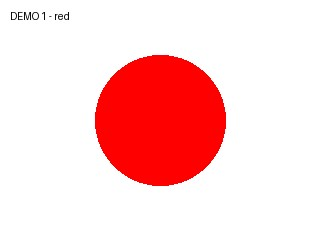

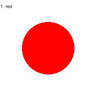

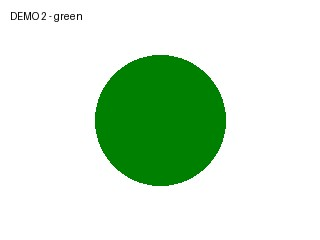

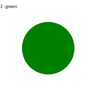

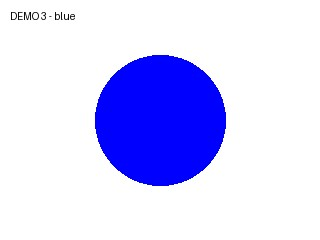

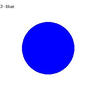

,file,original,original_pixels,original_bytes,output,output_pixels,output_bytes
0,demo_1.jpg,320x240,76800,5929,96x96,9216,3355
1,demo_2.jpg,320x240,76800,5831,96x96,9216,3515
2,demo_3.jpg,320x240,76800,6093,96x96,9216,3412


In [13]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageOps
import pandas as pd
from IPython.display import display

source_dir = Path("images_original")
output_dir = Path("images_96")
source_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)

# 실물 촬영 사진이 없는 경우에만 사용하는 합성 시연 데이터
if not any(p.suffix.lower() in {".jpg", ".jpeg", ".png"} for p in source_dir.iterdir()):
    for i, color in enumerate(["red", "green", "blue"], start=1):
        im = Image.new("RGB", (320, 240), "white")
        draw = ImageDraw.Draw(im)
        draw.ellipse((95, 55, 225, 185), fill=color)
        draw.text((10, 10), f"DEMO {i} - {color}", fill="black")
        im.save(source_dir / f"demo_{i}.jpg", quality=90)

records = []
for p in sorted(source_dir.iterdir()):
    if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue
    original = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
    w, h = original.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    result = original.crop((left, top, left + side, top + side))
    result = result.resize((96, 96), Image.Resampling.LANCZOS)
    dest = output_dir / f"{p.stem}_96.png"
    result.save(dest)
    assert result.size == (96, 96)
    records.append({"file": p.name, "original": f"{w}x{h}",
                    "original_pixels": w * h, "original_bytes": p.stat().st_size,
                    "output": "96x96", "output_pixels": 9216,
                    "output_bytes": dest.stat().st_size})
    print(p.name, "→", dest.name)
    display(original, result)
report = pd.DataFrame(records)
display(report)
report.to_csv("image_comparison.csv", index=False, encoding="utf-8-sig")


In [14]:
import zipfile
with zipfile.ZipFile("week09_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["esp32_sources", "images_original", "images_96"]:
        for p in sorted(Path(folder).rglob("*")):
            if p.is_file(): z.write(p,p.as_posix())
    z.write("image_comparison.csv")
display(FileLink("week09_results.zip"))


/workspace/scratch/eb1f2338bb51/week09_tutorial/week09_results.zip

### 기존 강의 Colab 워크북 3도 이어서 사용하기

- [학생용: 이미지 특성·리사이즈·Gradio·라벨 폴더](https://colab.research.google.com/github/itlects/2026-1_ai-convergence-apply/blob/main/week09_esp32_ai_image/colab/Week09_Workbook3_Image_Student.ipynb)
- [완성본 워크북 3](https://colab.research.google.com/github/itlects/2026-1_ai-convergence-apply/blob/main/week09_esp32_ai_image/colab/Week09_Workbook3_Image_Complete.ipynb)

## 결과 기록과 제출

| 예제 | 확인 기준 | 학생 기록 |
| --- | --- | --- |
| 1 | LED1~4 순차, 전체 약1.2초 | |
| 2 | 놓음1, 누름0, 버튼별 열 변화 | |
| 3 | 누르는 동안만 LED ON | |
| 4 | 262/294/330/349Hz, 음 길이250ms | |
| 5 | 토글·30ms·ALL ON, 멜로디 중 입력 지연 | |
| 6 | SD 용량, hello.txt 쓰기·읽기 | |
| 7 | JPEG3장, 해상도·파일크기·저장번호 | |
| 8 | AP 연결·갤러리·96×96 PNG | |
| Colab | 원본/96×96 비교, CSV·ZIP | |

| 질문 | 답변 |
| --- | --- |
| INPUT_PULLUP에서 누름이 LOW인 이유는? | |
| 누름 유지와 토글 동작의 차이는? | |
| 30ms 디바운스가 걸러내는 입력과 놓칠 수 있는 입력은? | |
| 축하 멜로디의 delay가 버튼 감시에 미치는 영향은? | |
| 예제8에서 보드와 브라우저가 맡는 처리는? | |
| 중앙 자르기의 정보 손실과 클래스별 수집 조건은? | |

**제출:** 자신의 Wokwi 사본 URL, 예제5 실행 화면·로그, 기록·질문표, 96×96 PNG3장, 비교 CSV. 카메라 보유자는 실제 JPEG3장·갤러리 화면을 추가하고 미보유자는 시연 데이터 사용을 표시한다.

## 오류 해결

| 증상 | 확인 |
| --- | --- |
| LED·버튼 반응 없음 | 최신 핀 표와 실제 코드 일치 → GND → LED극성·저항 → 버튼의 서로 다른 접점 → 실행 중 여부 |
| 한 번 누름 여러 토글 | 예제5 전체 코드, DEBOUNCE_MS=30, 완전히 놓고 재누름 |
| 멜로디 중 짧은 입력 놓침 | 예제5의 delay 구간에 의한 제한. 비차단 멜로디는 확장 과제 |
| 부저 무음 | 저전류 수동 피에조인지, 27번핀·극성·음량·브라우저 음소거 |
| S3 PSRAM 없음 | 보드 메모리 사양·OPI설정·보드 선택 확인 |
| SD 마운트 실패 | 전원 끄고 카드·FAT32·내부핀(CLK39,CMD38,D0 40) 확인 |
| 카메라 초기화 실패 | S3 제조사별 핀·PSRAM·케이블·안정적 전원. 실패 시 해상도 명령 중단 |
| 갤러리 접속 안 됨 | 시리얼 AP명·주소 확인, 해당 Wi-Fi 유지, 다른 네트워크 자동전환 확인 |
| Colab C++ 구문 오류 | Python 셀에서 C++ 직접 실행하지 말고 표시·저장 셀 사용 |

## 검증 범위

- 이 작업에서 최신 Wokwi 완성 회로·스마트 패널을 컴파일하고 버튼4개 토글·ALL ON을 확인했다.
- 이 노트북의 Python 셀은 로컬 Python/IPython에서 순차 실행했다. Colab 원격 실행·실물 카메라 촬영은 수행하지 않았다.
- 최신 원본 README에는 Arduino-ESP32 3.3.8로 예제1~8 컴파일 성공 기록이 있다. 본 작업에서 별도로 그 실물 업로드·동작을 검증한 것은 아니다.
- Wokwi용 sketch는 예제5와 같은 핀·효과음·디바운스·멜로디 로직을 읽기 쉽게 정리하고 로그를 영어로 표시했다. 원본 예제1~8도 별도로 함께 제공한다.
- [GitHub 검증 기록](https://github.com/itlects/2026-1_ai-convergence-apply/blob/main/week09_esp32_ai_image/tutorial/VALIDATION.md)
- [Wokwi ESP32 문서](https://docs.wokwi.com/guides/esp32) / [DevKitC V4 공식 가이드](https://docs.espressif.com/projects/esp-dev-kits/en/latest/esp32/esp32-devkitc/user_guide.html)
